## Clustering Track: Credit Card Customer Segmentation

## Problem Statement

A bank's marketing team holds the **usage behaviour of ~9,000 active credit-card holders over the last 6 months** (balances, purchases, cash advances, payments, credit limits, and the frequency of each activity). Today every customer receives roughly the same offers, which wastes marketing budget and misses revenue opportunities.

**Goal:** discover **natural groups (segments) of customers with similar credit-card usage behaviour**, using *unsupervised* learning, so that the bank can design **targeted marketing strategies** — for example:

* reward and retain high-spending, full-paying customers;
* offer instalment / EMI schemes to customers who split purchases;
* manage risk and offer balance-transfer products to customers who rely heavily on cash advances;
* run re-activation campaigns for customers who barely use the card.

**This is a clustering problem:** the dataset has **no target / ground-truth label**, so the models are fitted without labels and judged with *internal* validity indices (Silhouette, Davies-Bouldin, Calinski-Harabasz) plus **business interpretability** of the resulting segments.

### Objectives
1. Audit and explore the data (EDA) and explain every visualisation.
2. Clean the data, engineer behaviour-based features and scale them.
3. Fit **K-Means** (Elbow curve to choose *k*) and **Agglomerative Hierarchical Clustering** (Dendrogram, linkage comparison).
4. Evaluate both with **Silhouette, Davies-Bouldin and Calinski-Harabasz** scores.
5. Visualise clusters with **PCA (2 components)** and **t-SNE**.
6. Profile each segment in business language, validate stability, and **save all models** for later use / deployment.

## 1. Setup & Configuration

In [1]:
import warnings, json, sys, gc, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from scipy.cluster.hierarchy import linkage, dendrogram, cophenet, fcluster
from scipy.spatial.distance import pdist

import sklearn
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestCentroid
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import (silhouette_score, silhouette_samples,
                             davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score)

warnings.filterwarnings("ignore")
sys.setrecursionlimit(20000)   # SciPy dendrograms of chained trees (single linkage) are deeply recursive

# ---------- reproducibility ----------
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# ---------- plotting style (colour-blind friendly palette, as required by the guidelines) ----------
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
PALETTE = sns.color_palette("colorblind", 10)
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 13, "axes.titleweight": "bold",
                     "axes.labelsize": 11})
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

# ---------- folder layout (works whether the notebook is run from /notebooks or from the repo root) ----------
CWD  = Path.cwd()
ROOT = CWD.parent if CWD.name.lower() == "notebooks" else CWD
DATA_DIR, MODEL_DIR, APP_DIR = ROOT / "data", ROOT / "models", ROOT / "app"
FIG_DIR = ROOT / "figures" / "clustering"
for d in (DATA_DIR, MODEL_DIR, APP_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

print(f"Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}")
print("Project root :", ROOT)


def finish(name):
    # Tidy layout, save the current figure to figures/clustering/<name>.png and show it.
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()


def evaluate_clustering(X, labels):
    # Return the three mandatory internal validity indices for one clustering result.
    return {"Silhouette": silhouette_score(X, labels),
            "Davies-Bouldin": davies_bouldin_score(X, labels),
            "Calinski-Harabasz": calinski_harabasz_score(X, labels)}


def find_elbow(ks, values):
    # Elbow = point furthest from the straight line joining the first and last point
    # of the (normalised) curve ('kneedle'-style geometric rule).
    k = np.asarray(list(ks), float); y = np.asarray(values, float)
    kn = (k - k.min()) / (k.max() - k.min()); yn = (y - y.min()) / (y.max() - y.min())
    dx, dy = kn[-1] - kn[0], yn[-1] - yn[0]
    dist = np.abs(dx * (yn - yn[0]) - dy * (kn - kn[0])) / np.hypot(dx, dy)
    return int(k[np.argmax(dist)])


def silhouette_plot(ax, X, labels, title):
    # Silhouette 'knife' plot: one horizontal band per cluster, width = silhouette of each sample.
    s = silhouette_samples(X, labels); avg = s.mean(); y_low = 10
    for i, c in enumerate(np.unique(labels)):
        vals = np.sort(s[labels == c]); y_up = y_low + len(vals)
        ax.fill_betweenx(np.arange(y_low, y_up), 0, vals, color=PALETTE[i % 10], alpha=0.85)
        ax.text(-0.07, y_low + 0.5 * len(vals), f"C{c}", fontsize=9, va="center")
        y_low = y_up + 10
    ax.axvline(avg, color="red", ls="--", label=f"mean = {avg:.3f}")
    ax.set(title=title, xlabel="Silhouette coefficient", ylabel="Samples (grouped by cluster)", yticks=[])
    ax.legend(loc="lower right")

Python 3.12.4 | numpy 2.3.5 | pandas 2.2.3 | scikit-learn 1.8.0
Project root : d:\III Year\ml\vectora_final\Vectora\Clustering


## 2. Data Loading & Audit

In [2]:
import shutil

def find_dataset():
    # Search the usual locations for the Kaggle CSV (file name contains both 'cc' and 'general').
    folders = [DATA_DIR, ROOT, Path.cwd(), Path("/kaggle/input/ccdata"), Path("/content")]
    for folder in folders:
        if folder.exists():
            for p in folder.glob("*.csv"):
                n = p.name.lower()
                if "cc" in n and "general" in n:
                    return p
    # Fallback: try to download from Kaggle
    try:
        import kagglehub
        dl = Path(kagglehub.dataset_download("arjunbhasin2013/ccdata"))
        for p in dl.rglob("*.csv"):
            return p
    except Exception as e:
        print("kagglehub download failed:", e)
    return None

DATA_PATH = find_dataset()
if DATA_PATH is None:
    raise FileNotFoundError("Place 'CC GENERAL.csv' (Kaggle: arjunbhasin2013/ccdata) inside the 'data/' folder and re-run.")

# keep a copy inside data/ so that the repository is self-contained
if DATA_PATH.parent != DATA_DIR:
    shutil.copy(DATA_PATH, DATA_DIR / DATA_PATH.name)

df_raw = pd.read_csv(DATA_PATH)
print("Loaded:", DATA_PATH)
df_raw.head()

Loaded: d:\III Year\ml\vectora_final\Vectora\Clustering\data\CC GENERAL.csv


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.901,0.818,95.400,0.000,95.400,0.000,0.167,0.000,0.083,0.000,0,2,"1,000.000",201.802,139.510,0.000,12
1,C10002,"3,202.467",0.909,0.000,0.000,0.000,"6,442.945",0.000,0.000,0.000,0.250,4,0,"7,000.000","4,103.033","1,072.340",0.222,12
2,C10003,"2,495.149",1.000,773.170,773.170,0.000,0.000,1.000,1.000,0.000,0.000,0,12,"7,500.000",622.067,627.285,0.000,12
3,C10004,"1,666.671",0.636,"1,499.000","1,499.000",0.000,205.788,0.083,0.083,0.000,0.083,1,1,"7,500.000",0.000,NaN,0.000,12
4,C10005,817.714,1.000,16.000,16.000,0.000,0.000,0.083,0.083,0.000,0.000,0,1,"1,200.000",678.335,244.791,0.000,12


In [3]:
print(f"Shape            : {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
print(f"Unique CUST_ID   : {df_raw['CUST_ID'].nunique():,}  (duplicated IDs: {df_raw['CUST_ID'].duplicated().sum()})")
print(f"Duplicate rows   : {df_raw.duplicated().sum()} (full-row) | {df_raw.drop(columns='CUST_ID').duplicated().sum()} (ignoring CUST_ID)")
print("Label column     : none -> unsupervised problem\n")

audit = pd.DataFrame({"dtype": df_raw.dtypes.astype(str),
                      "non_null": df_raw.notna().sum(),
                      "missing": df_raw.isna().sum(),
                      "missing_%": df_raw.isna().mean() * 100,
                      "n_unique": df_raw.nunique()})
audit

Shape            : 8,950 rows x 18 columns
Unique CUST_ID   : 8,950  (duplicated IDs: 0)
Duplicate rows   : 0 (full-row) | 0 (ignoring CUST_ID)
Label column     : none -> unsupervised problem



,dtype,non_null,missing,missing_%,n_unique
CUST_ID,object,8950,0,0.000,8950
BALANCE,float64,8950,0,0.000,8871
BALANCE_FREQUENCY,float64,8950,0,0.000,43
PURCHASES,float64,8950,0,0.000,6203
ONEOFF_PURCHASES,float64,8950,0,0.000,4014
INSTALLMENTS_PURCHASES,float64,8950,0,0.000,4452
CASH_ADVANCE,float64,8950,0,0.000,4323
PURCHASES_FREQUENCY,float64,8950,0,0.000,47
ONEOFF_PURCHASES_FREQUENCY,float64,8950,0,0.000,47
PURCHASES_INSTALLMENTS_FREQUENCY,float64,8950,0,0.000,47


In [4]:
# Summary statistics of the 17 behavioural features
RAW_FEATURES = [c for c in df_raw.columns if c != "CUST_ID"]
df_raw[RAW_FEATURES].describe(percentiles=[.25, .5, .75, .95, .99]).T

,count,mean,std,min,25%,50%,75%,95%,99%,max
BALANCE,"8,950.000","1,564.475","2,081.532",0.000,128.282,873.385,"2,054.140","5,909.112","9,338.805","19,043.139"
BALANCE_FREQUENCY,"8,950.000",0.877,0.237,0.000,0.889,1.000,1.000,1.000,1.000,1.000
PURCHASES,"8,950.000","1,003.205","2,136.635",0.000,39.635,361.280,"1,110.130","3,998.619","8,977.290","49,039.570"
ONEOFF_PURCHASES,"8,950.000",592.437,"1,659.888",0.000,0.000,38.000,577.405,"2,671.094","6,689.898","40,761.250"
INSTALLMENTS_PURCHASES,"8,950.000",411.068,904.338,0.000,0.000,89.000,468.637,"1,750.087","3,886.241","22,500.000"
CASH_ADVANCE,"8,950.000",978.871,"2,097.164",0.000,0.000,0.000,"1,113.821","4,647.169","9,588.163","47,137.212"
PURCHASES_FREQUENCY,"8,950.000",0.490,0.401,0.000,0.083,0.500,0.917,1.000,1.000,1.000
ONEOFF_PURCHASES_FREQUENCY,"8,950.000",0.202,0.298,0.000,0.000,0.083,0.300,1.000,1.000,1.000
PURCHASES_INSTALLMENTS_FREQUENCY,"8,950.000",0.364,0.397,0.000,0.000,0.167,0.750,1.000,1.000,1.000
CASH_ADVANCE_FREQUENCY,"8,950.000",0.135,0.200,0.000,0.000,0.000,0.222,0.583,0.833,1.500


## 3. Exploratory Data Analysis (EDA)

### 3.1 Missing-value profile

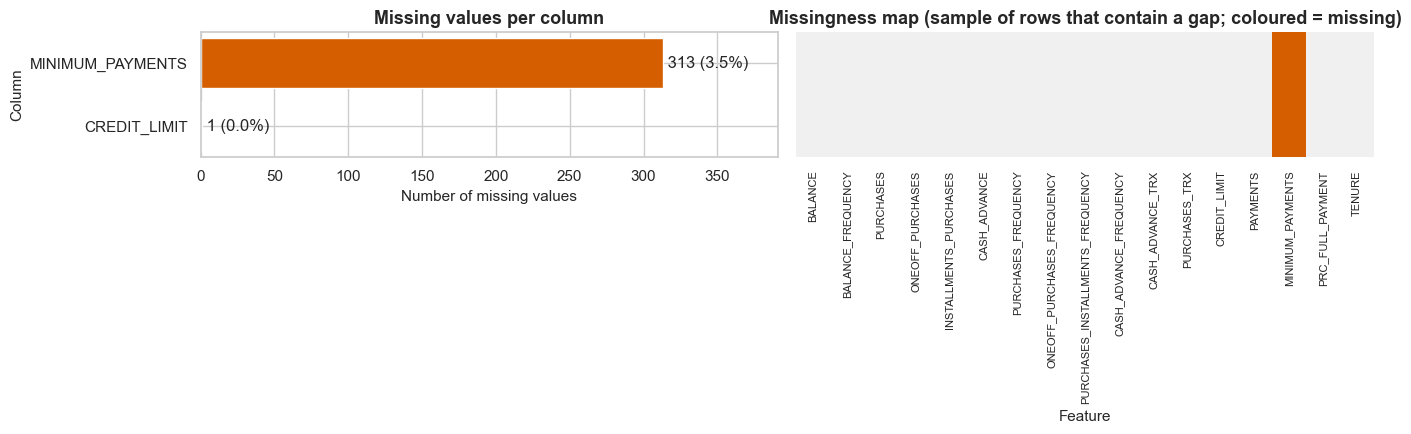

In [5]:
miss = df_raw.isna().sum().sort_values(ascending=False)
miss = miss[miss > 0]

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].barh(miss.index[::-1], miss.values[::-1], color=PALETTE[3])
for i, v in enumerate(miss.values[::-1]):
    ax[0].text(v, i, f" {v} ({v/len(df_raw):.1%})", va="center")
ax[0].set(title="Missing values per column", xlabel="Number of missing values", ylabel="Column")
ax[0].set_xlim(0, miss.max() * 1.25)

rows_with_na = df_raw[df_raw.isna().any(axis=1)]
sns.heatmap(rows_with_na[RAW_FEATURES].isna().astype(int).sample(min(150, len(rows_with_na)), random_state=RANDOM_STATE),
            cmap=["#f0f0f0", PALETTE[3]], cbar=False, yticklabels=False, ax=ax[1])
ax[1].set(title="Missingness map (sample of rows that contain a gap; coloured = missing)", xlabel="Feature")
plt.setp(ax[1].get_xticklabels(), rotation=90, fontsize=8)
finish("01_missing_values")

**Observations**
* Missing data is **concentrated in a single column, `MINIMUM_PAYMENTS`** (about 3.5 % of customers); `CREDIT_LIMIT` has just one missing entry.
* In the missingness map nearly every affected row is blank in `MINIMUM_PAYMENTS` only, i.e. the gaps are **not spread across many columns**, so no row needs to be discarded.
* Because the proportion is small, **imputation (not row deletion)** is appropriate; the choice of statistic is discussed in Section 4.1 after we inspect who these customers are.

### 3.2 Distribution of every feature

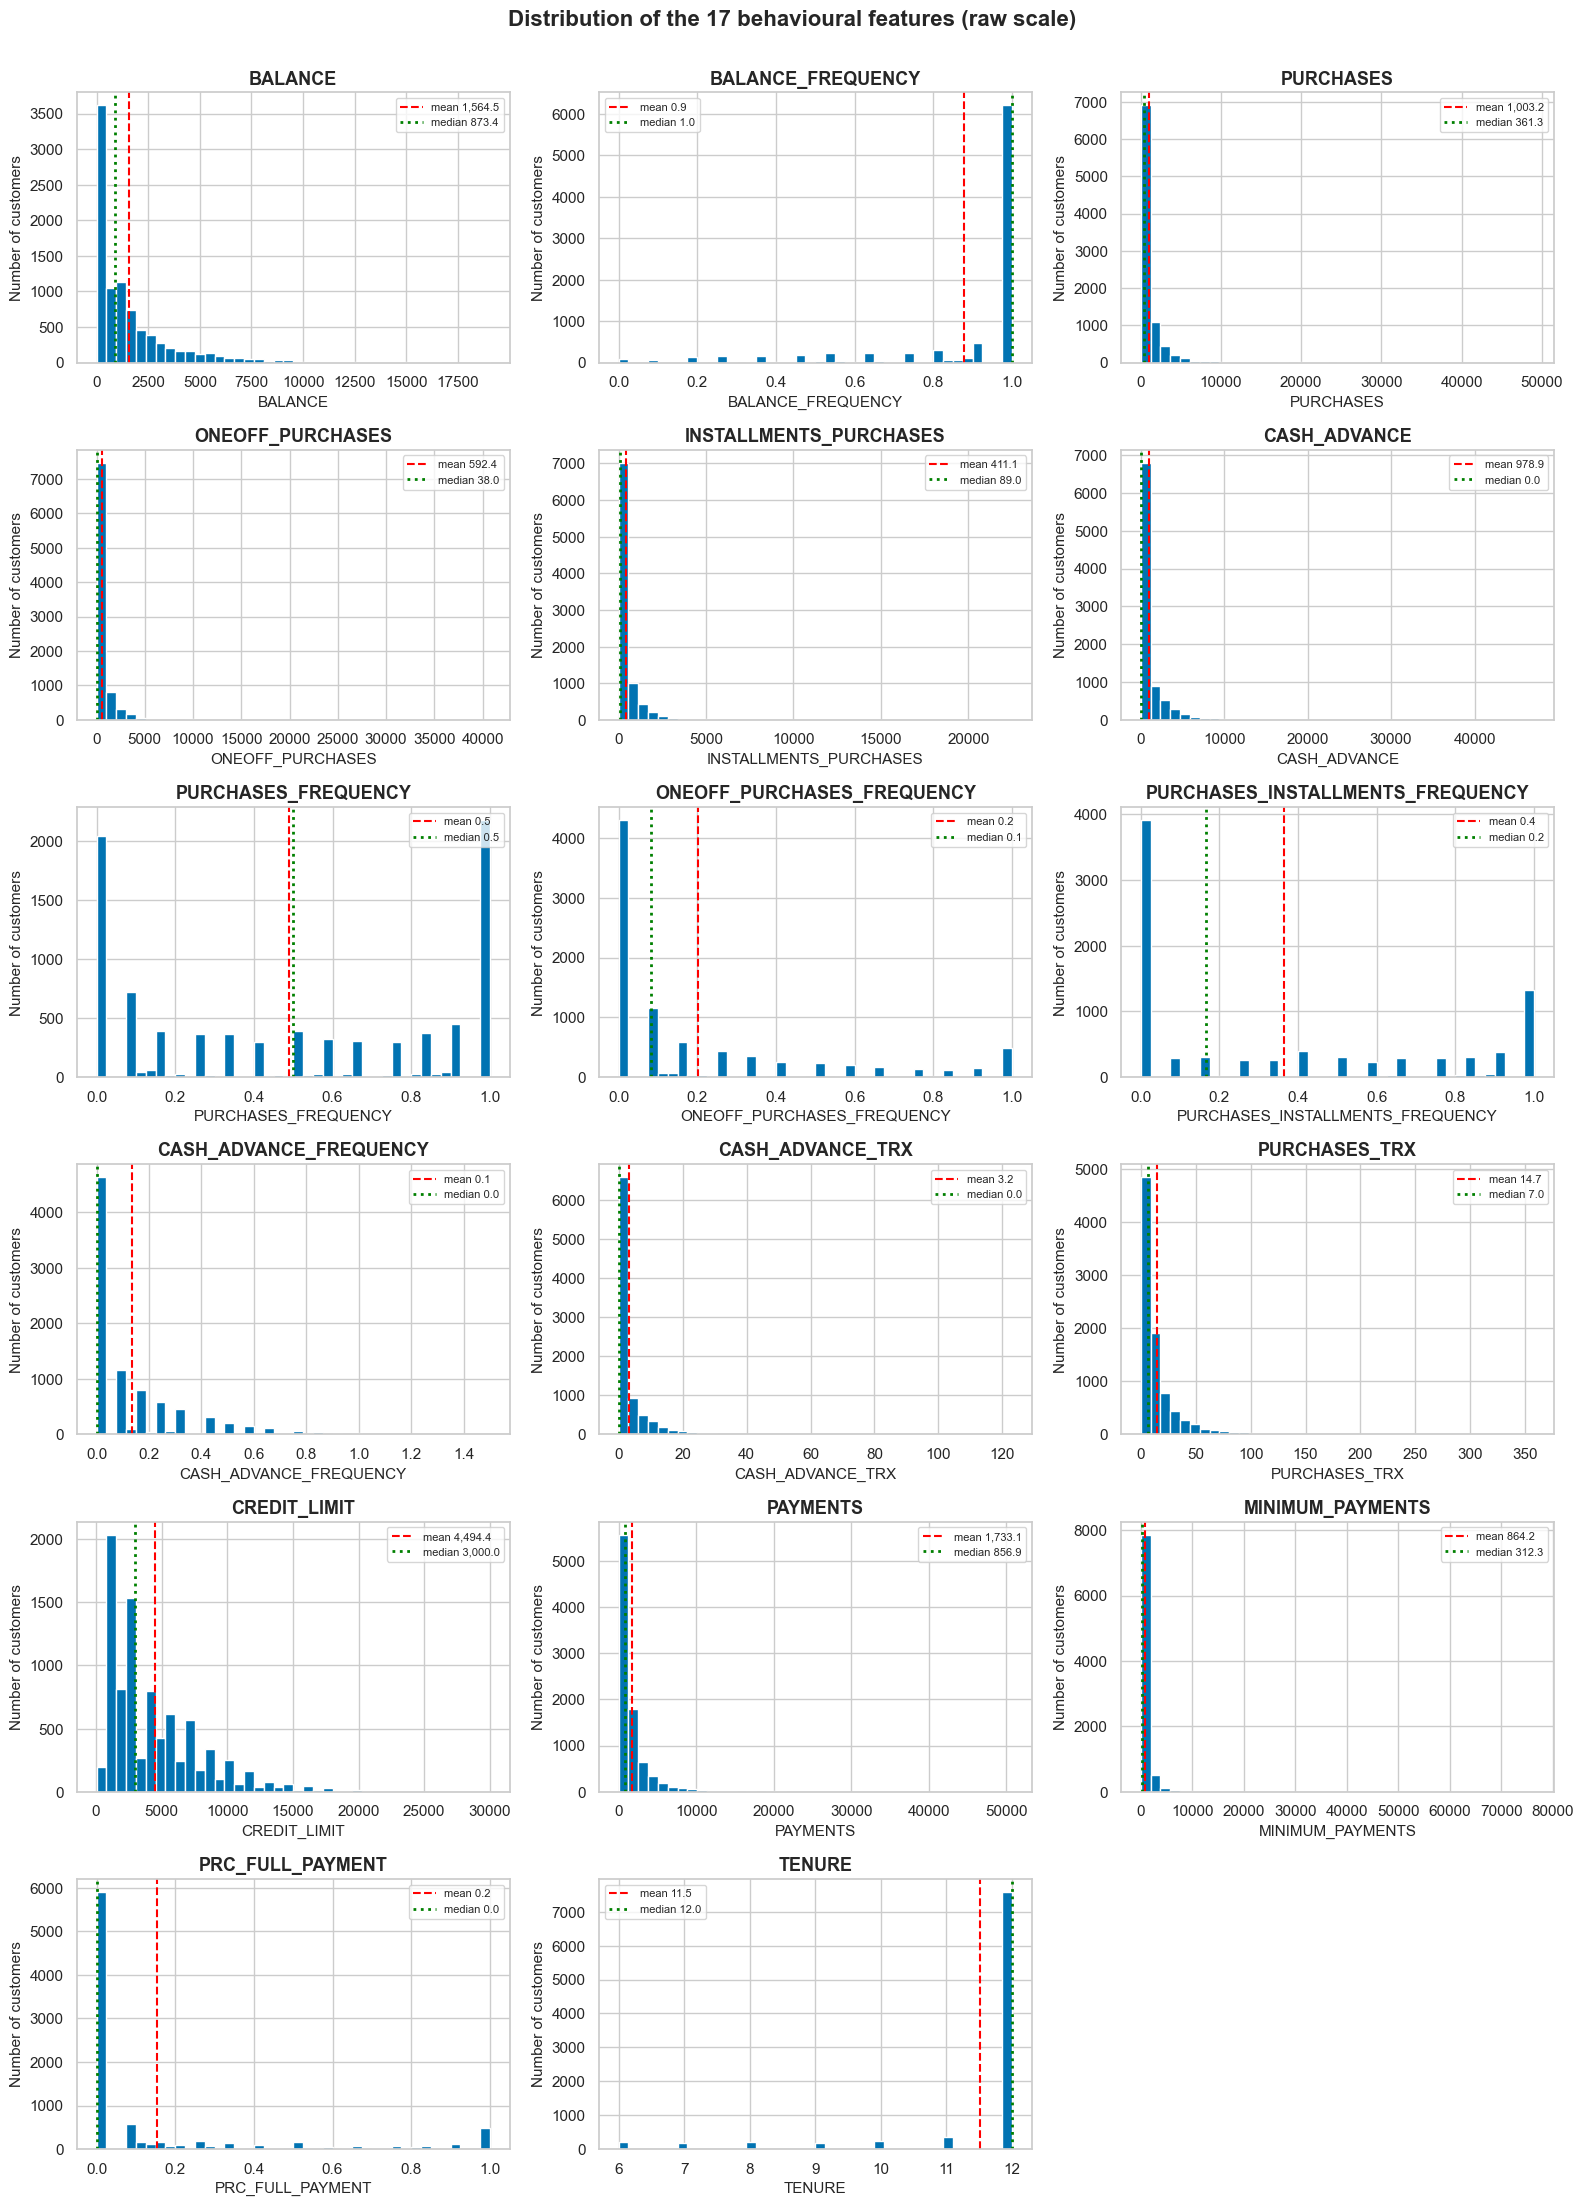

In [6]:
fig, axes = plt.subplots(6, 3, figsize=(16, 22))
for ax, col in zip(axes.ravel(), RAW_FEATURES):
    data = df_raw[col].dropna()
    ax.hist(data, bins=40, color=PALETTE[0], edgecolor="white")
    ax.axvline(data.mean(), color="red", ls="--", lw=1.5, label=f"mean {data.mean():,.1f}")
    ax.axvline(data.median(), color="green", ls=":", lw=2, label=f"median {data.median():,.1f}")
    ax.set(title=col, xlabel=col, ylabel="Number of customers")
    ax.legend(fontsize=8)
for ax in axes.ravel()[len(RAW_FEATURES):]:
    ax.axis("off")
plt.suptitle("Distribution of the 17 behavioural features (raw scale)", fontsize=16, fontweight="bold", y=1.002)
finish("02_feature_distributions")

**Observations**
* **Monetary / count variables** (`BALANCE`, `PURCHASES`, `ONEOFF_PURCHASES`, `INSTALLMENTS_PURCHASES`, `CASH_ADVANCE`, `PAYMENTS`, `MINIMUM_PAYMENTS`, `CASH_ADVANCE_TRX`, `PURCHASES_TRX`, `CREDIT_LIMIT`) are **extremely right-skewed**: most customers sit near zero and a small number reach tens of thousands. The mean is clearly to the right of the median in every one of these plots.
* **Large spikes at exactly 0** appear for `ONEOFF_PURCHASES`, `INSTALLMENTS_PURCHASES`, `CASH_ADVANCE`, `CASH_ADVANCE_TRX` and the related frequencies — many customers simply never use that feature of the card. This hints at distinct behavioural groups (e.g. "uses cash advance" vs "never does").
* **Frequency variables** are bounded in [0, 1] and often **bimodal with peaks at 0 and 1** (`BALANCE_FREQUENCY` is concentrated near 1; `PURCHASES_FREQUENCY` has a big mass at both ends) — customers tend to be either very active or very inactive, rather than "average".
* `PRC_FULL_PAYMENT` has a very large spike at 0: most customers **rarely pay the full statement balance** and therefore revolve debt.
* `TENURE` is almost constant (the large majority have 12 months), so it will contribute little to separating customers.
* **Implication:** without a transformation, a handful of very large values would dominate Euclidean distances and K-Means would mostly separate "rich outliers" from everyone else. We will apply a `log1p` transformation to the skewed variables (Section 4).

### 3.3 Skewness ranking


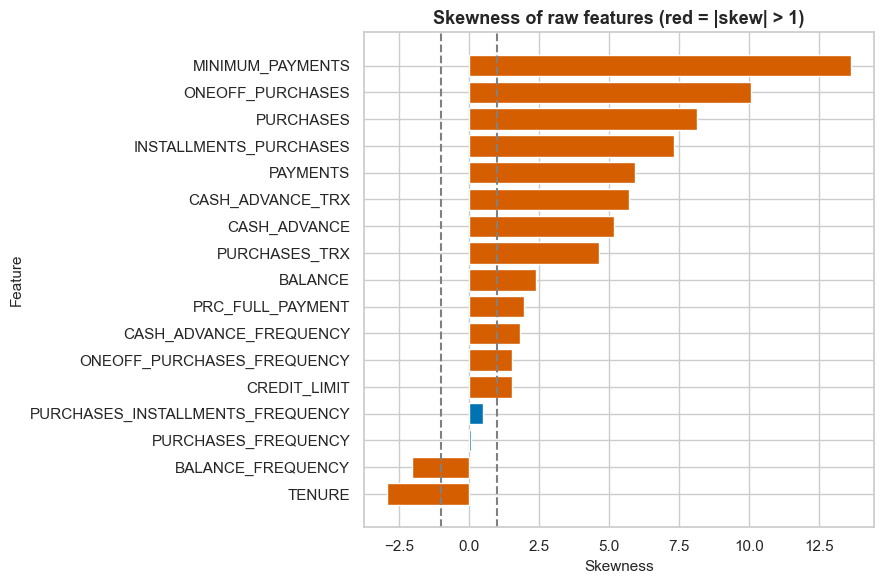

Features with |skew| > 1: ['TENURE', 'BALANCE_FREQUENCY', 'CREDIT_LIMIT', 'ONEOFF_PURCHASES_FREQUENCY', 'CASH_ADVANCE_FREQUENCY', 'PRC_FULL_PAYMENT', 'BALANCE', 'PURCHASES_TRX', 'CASH_ADVANCE', 'CASH_ADVANCE_TRX', 'PAYMENTS', 'INSTALLMENTS_PURCHASES', 'PURCHASES', 'ONEOFF_PURCHASES', 'MINIMUM_PAYMENTS']


In [7]:
skew_raw = df_raw[RAW_FEATURES].skew().sort_values()
fig, ax = plt.subplots(figsize=(9, 6))
colors = [PALETTE[3] if abs(v) > 1 else PALETTE[0] for v in skew_raw.values]
ax.barh(skew_raw.index, skew_raw.values, color=colors)
ax.axvline(1, color="grey", ls="--"); ax.axvline(-1, color="grey", ls="--")
ax.set(title="Skewness of raw features (red = |skew| > 1)", xlabel="Skewness", ylabel="Feature")
finish("03_skewness_raw")
print("Features with |skew| > 1:", list(skew_raw[skew_raw.abs() > 1].index))

**Observations**
* Almost all monetary and transaction-count variables have **skewness well above 1** (several are above 5 — e.g. the purchase variables and `MINIMUM_PAYMENTS`), confirming the heavy right tails.
* The frequency variables, `PRC_FULL_PAYMENT` and `BALANCE_FREQUENCY` are far less skewed (and `BALANCE_FREQUENCY` / `TENURE` are skewed to the *left*), so they do **not** need a log transform.
* This gives a data-driven split: **log-transform the skewed monetary / count variables; leave the bounded frequency variables as they are.**

### 3.4 Outlier detection (box plots + IQR rule)

,BALANCE_FREQUENCY,PRC_FULL_PAYMENT,TENURE,CASH_ADVANCE,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,MINIMUM_PAYMENTS,PAYMENTS,PURCHASES,CASH_ADVANCE_TRX,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_TRX,BALANCE,CASH_ADVANCE_FREQUENCY,CREDIT_LIMIT,PURCHASES_INSTALLMENTS_FREQUENCY,PURCHASES_FREQUENCY
outliers,"1,493.000","1,474.000","1,366.000","1,030.000","1,013.000",867.000,841.000,808.000,808.000,804.000,782.000,766.000,695.000,525.000,248.000,0.000,0.000
outliers_%,16.682,16.469,15.263,11.508,11.318,9.687,9.397,9.028,9.028,8.983,8.737,8.559,7.765,5.866,2.771,0.000,0.000


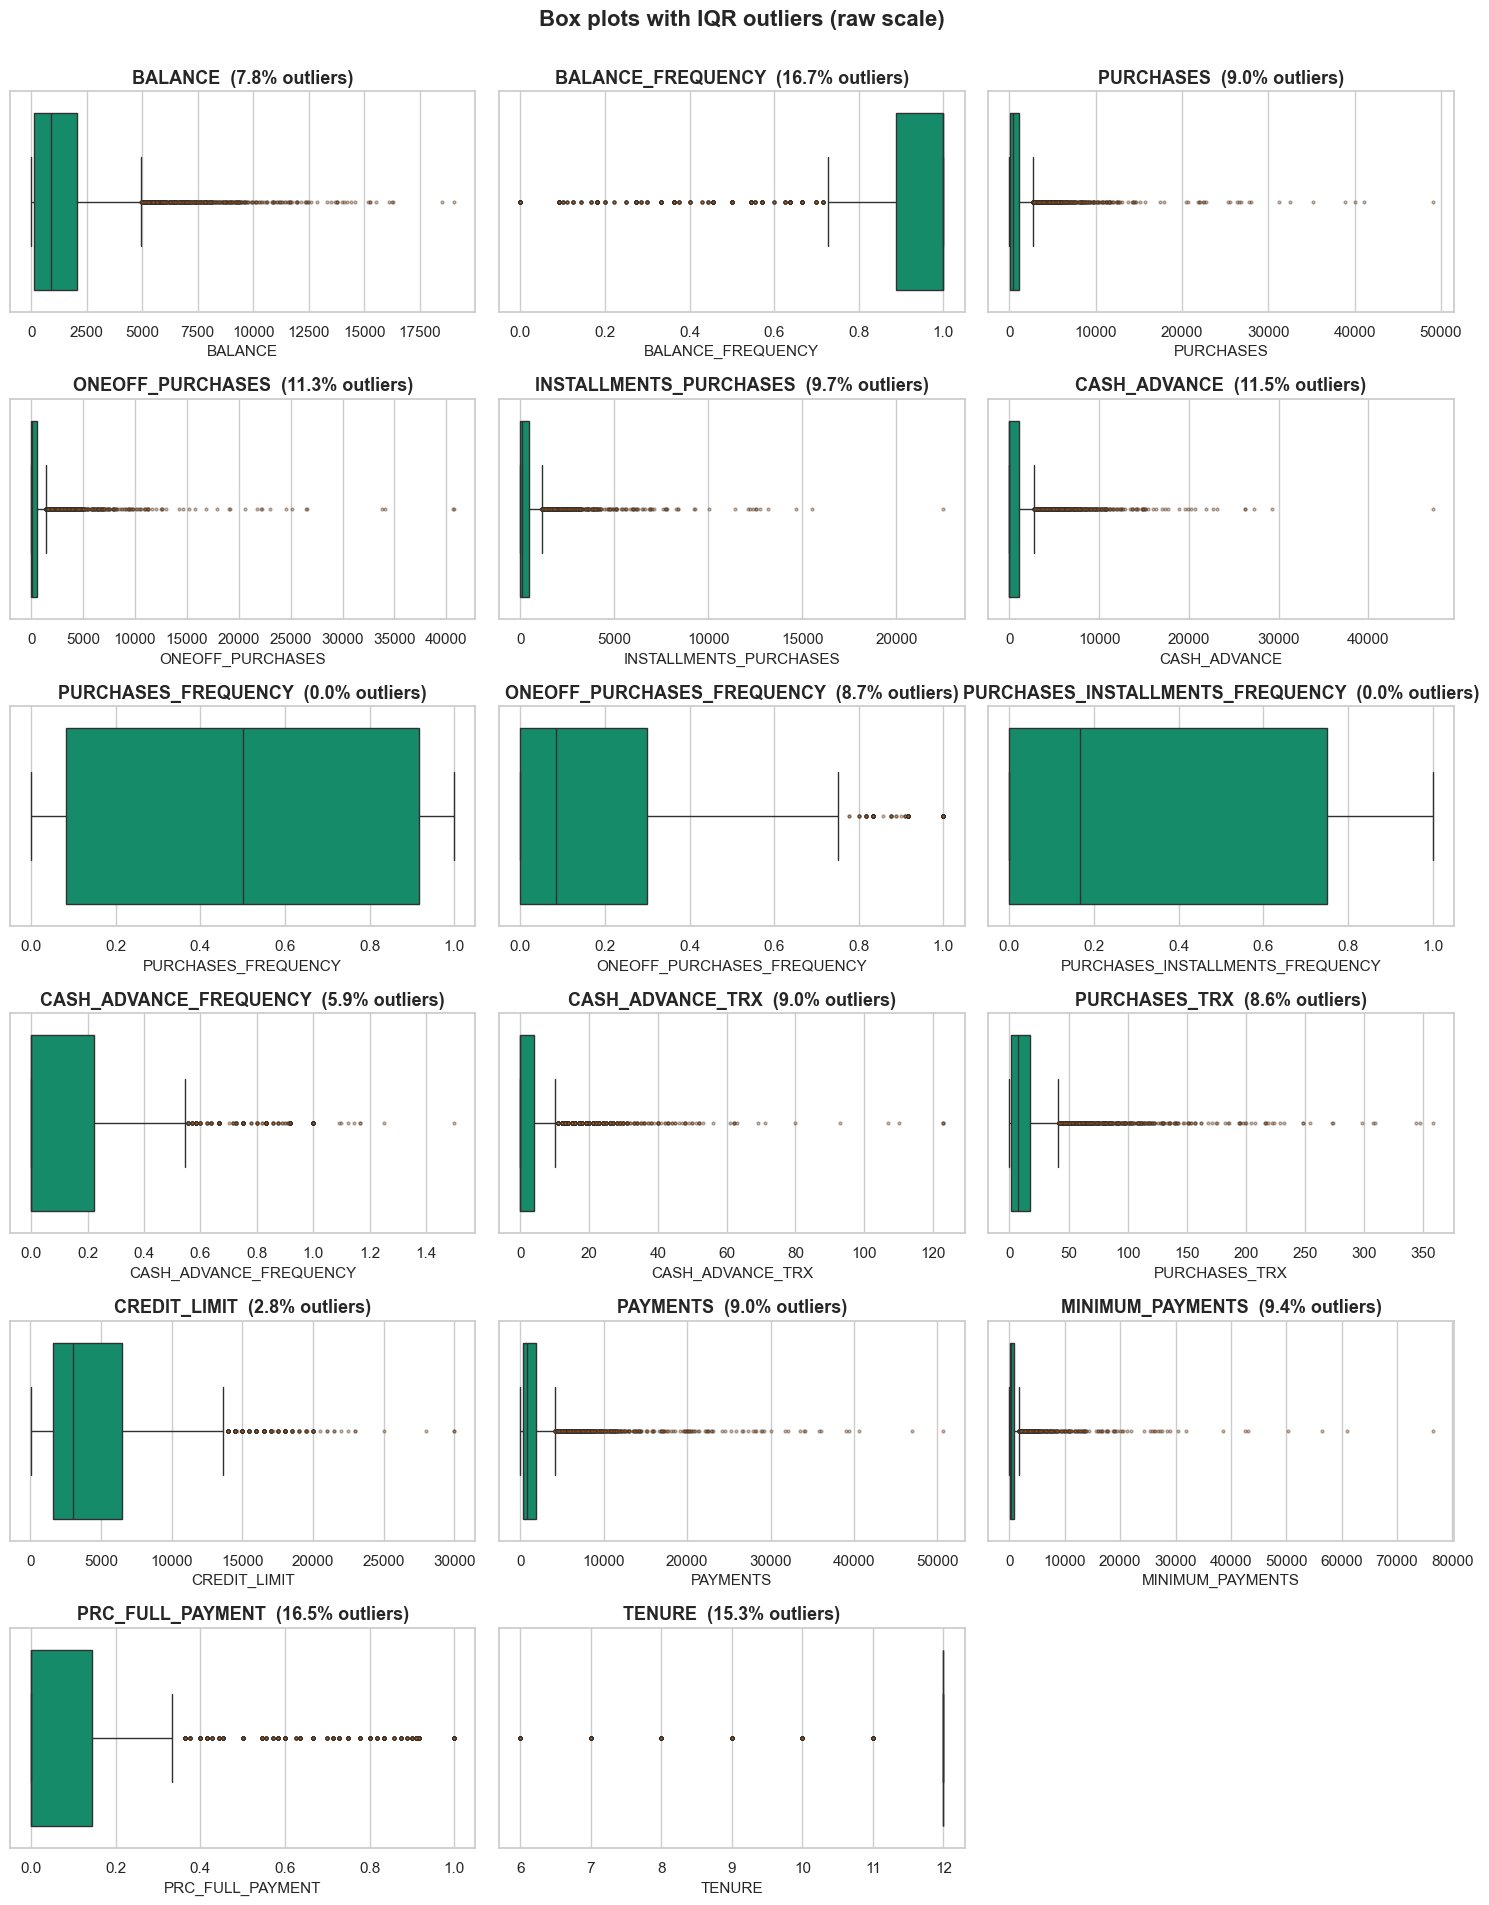

In [8]:
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

out_tbl = pd.DataFrame({"outliers": {c: iqr_outliers(df_raw[c].dropna()) for c in RAW_FEATURES}})
out_tbl["outliers_%"] = out_tbl["outliers"] / len(df_raw) * 100
display(out_tbl.sort_values("outliers", ascending=False).T)

fig, axes = plt.subplots(6, 3, figsize=(15, 19))
for ax, col in zip(axes.ravel(), RAW_FEATURES):
    sns.boxplot(x=df_raw[col], ax=ax, color=PALETTE[2], fliersize=2, flierprops=dict(markerfacecolor=PALETTE[3], alpha=.4))
    ax.set(title=f"{col}  ({out_tbl.loc[col, 'outliers_%']:.1f}% outliers)", xlabel=col)
for ax in axes.ravel()[len(RAW_FEATURES):]:
    ax.axis("off")
plt.suptitle("Box plots with IQR outliers (raw scale)", fontsize=16, fontweight="bold", y=1.002)
finish("04_boxplots_outliers")

**Observations**
* The monetary features flag a **very large share of customers as "outliers"** (often 8 – 15 % or more), which is typical of heavy-tailed data rather than of data-entry errors.
* Bounded variables (`*_FREQUENCY`, `PRC_FULL_PAYMENT`) show few or no outliers — their range is naturally limited.
* **Decision (see Section 4.2):** these extreme values are **genuine high-value customers** — exactly the segment the bank cares most about — so we do **not delete them**. Deleting 10 %+ of rows would also throw away a whole segment. Instead we **compress the tails with a `log1p` transform**, which keeps every customer but stops a few giant values from dominating the distance computations.

### 3.5 Customer behaviour flags & tenure

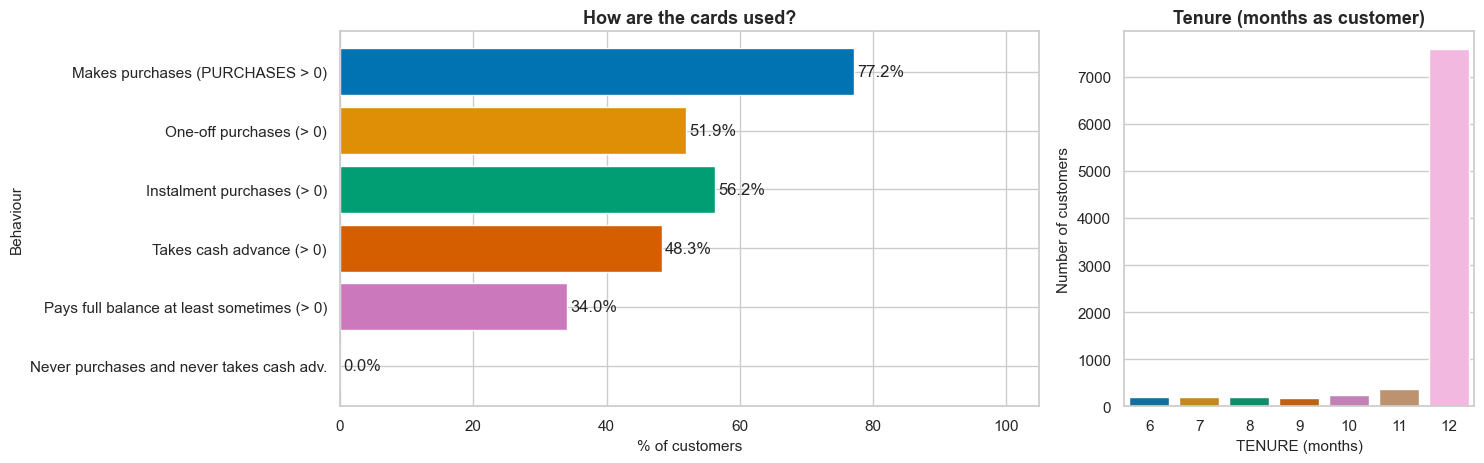

In [9]:
flags = pd.Series({
    "Makes purchases (PURCHASES > 0)":            (df_raw.PURCHASES > 0).mean(),
    "One-off purchases (> 0)":                    (df_raw.ONEOFF_PURCHASES > 0).mean(),
    "Instalment purchases (> 0)":                 (df_raw.INSTALLMENTS_PURCHASES > 0).mean(),
    "Takes cash advance (> 0)":                   (df_raw.CASH_ADVANCE > 0).mean(),
    "Pays full balance at least sometimes (> 0)": (df_raw.PRC_FULL_PAYMENT > 0).mean(),
    "Never purchases and never takes cash adv.":  ((df_raw.PURCHASES == 0) & (df_raw.CASH_ADVANCE == 0)).mean()}) * 100

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [2, 1]})
bars = ax[0].barh(flags.index[::-1], flags.values[::-1], color=PALETTE[:6][::-1])
for b, v in zip(bars, flags.values[::-1]):
    ax[0].text(v + 0.5, b.get_y() + b.get_height() / 2, f"{v:.1f}%", va="center")
ax[0].set(title="How are the cards used?", xlabel="% of customers", ylabel="Behaviour", xlim=(0, 105))

tenure_counts = df_raw["TENURE"].value_counts().sort_index()
sns.barplot(x=tenure_counts.index, y=tenure_counts.values, ax=ax[1], palette="colorblind", hue=tenure_counts.index, legend=False)
ax[1].set(title="Tenure (months as customer)", xlabel="TENURE (months)", ylabel="Number of customers")
finish("05_behaviour_flags_tenure")

**Observations**
* The bulk of customers (roughly **85 – 90 %**) buy with the card, whereas only about **half** ever take a cash advance — so cash-advance use is a real differentiator.
* One-off and instalment purchases each cover only part of the base and overlap partially, suggesting groups such as *"one-off buyers"*, *"instalment buyers"* and *"both"*.
* A small but non-trivial fraction of customers **neither purchase nor take cash advances** — a dormant group that a re-activation campaign could target.
* **Tenure is dominated by 12 months** (about 80 % of customers); the other tenures are small. Since almost everybody has the same tenure, it will hardly influence the clusters, but we keep it because tenure is a legitimate customer characteristic.

### 3.6 Correlation heatmap

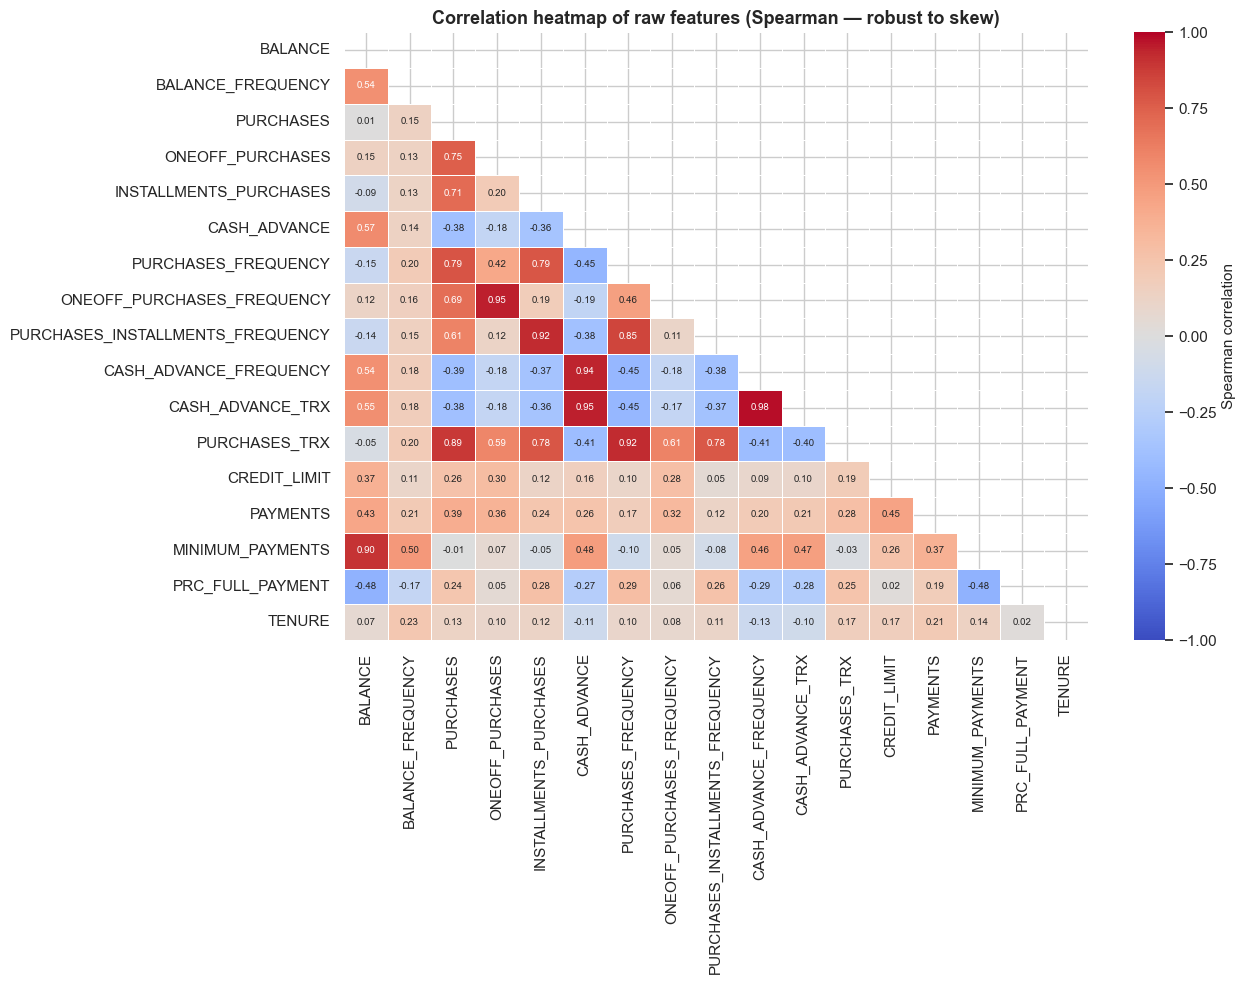

Top 10 most correlated feature pairs:


,feature_1,feature_2,rho
0,CASH_ADVANCE_TRX,CASH_ADVANCE_FREQUENCY,0.983
1,ONEOFF_PURCHASES_FREQUENCY,ONEOFF_PURCHASES,0.952
2,CASH_ADVANCE_TRX,CASH_ADVANCE,0.952
3,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE,0.941
4,PURCHASES_TRX,PURCHASES_FREQUENCY,0.924
5,PURCHASES_INSTALLMENTS_FREQUENCY,INSTALLMENTS_PURCHASES,0.923
6,MINIMUM_PAYMENTS,BALANCE,0.900
7,PURCHASES_TRX,PURCHASES,0.885
8,PURCHASES_INSTALLMENTS_FREQUENCY,PURCHASES_FREQUENCY,0.852
9,PURCHASES_FREQUENCY,PURCHASES,0.795


In [10]:
corr = df_raw[RAW_FEATURES].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", annot_kws={"size": 7}, cmap="coolwarm", center=0,
            vmin=-1, vmax=1, linewidths=.4, cbar_kws={"label": "Spearman correlation"}, ax=ax)
ax.set(title="Correlation heatmap of raw features (Spearman — robust to skew)")
finish("06_correlation_heatmap")

pairs = (corr.where(~mask).stack().rename("rho").reset_index()
         .rename(columns={"level_0": "feature_1", "level_1": "feature_2"}))
pairs["abs_rho"] = pairs.rho.abs()
print("Top 10 most correlated feature pairs:")
display(pairs.sort_values("abs_rho", ascending=False).head(10).drop(columns="abs_rho").reset_index(drop=True))

**Observations**
* The strongest relationships are **structural**: `PURCHASES` ↔ `ONEOFF_PURCHASES` and `PURCHASES` ↔ `INSTALLMENTS_PURCHASES` (a customer's total purchases are the sum of the two types), `PURCHASES_FREQUENCY` ↔ `PURCHASES_INSTALLMENTS_FREQUENCY` / `ONEOFF_PURCHASES_FREQUENCY`, `PURCHASES` ↔ `PURCHASES_TRX`, and `CASH_ADVANCE` ↔ `CASH_ADVANCE_TRX` ↔ `CASH_ADVANCE_FREQUENCY`.
* Two **clear feature "families"** appear as blocks: a *purchase family* and a *cash-advance family*; the two families are weakly or even negatively related to each other, i.e. customers who buy a lot tend **not** to be the ones who take cash advances.
* `BALANCE` is moderately correlated with `CASH_ADVANCE` and `CREDIT_LIMIT`; `PAYMENTS` is moderately correlated with `PURCHASES` (customers who spend more also pay more).
* `TENURE` is nearly uncorrelated with everything, again confirming its low discriminating power.
* **Implication:** because families of features are redundant, the data's *effective* dimensionality is much lower than 17. This motivates the PCA analysis in Section 5 and explains why a small number of clusters (≈ 3 – 6) should be enough.

### 3.7 Scatter plots of key feature relationships

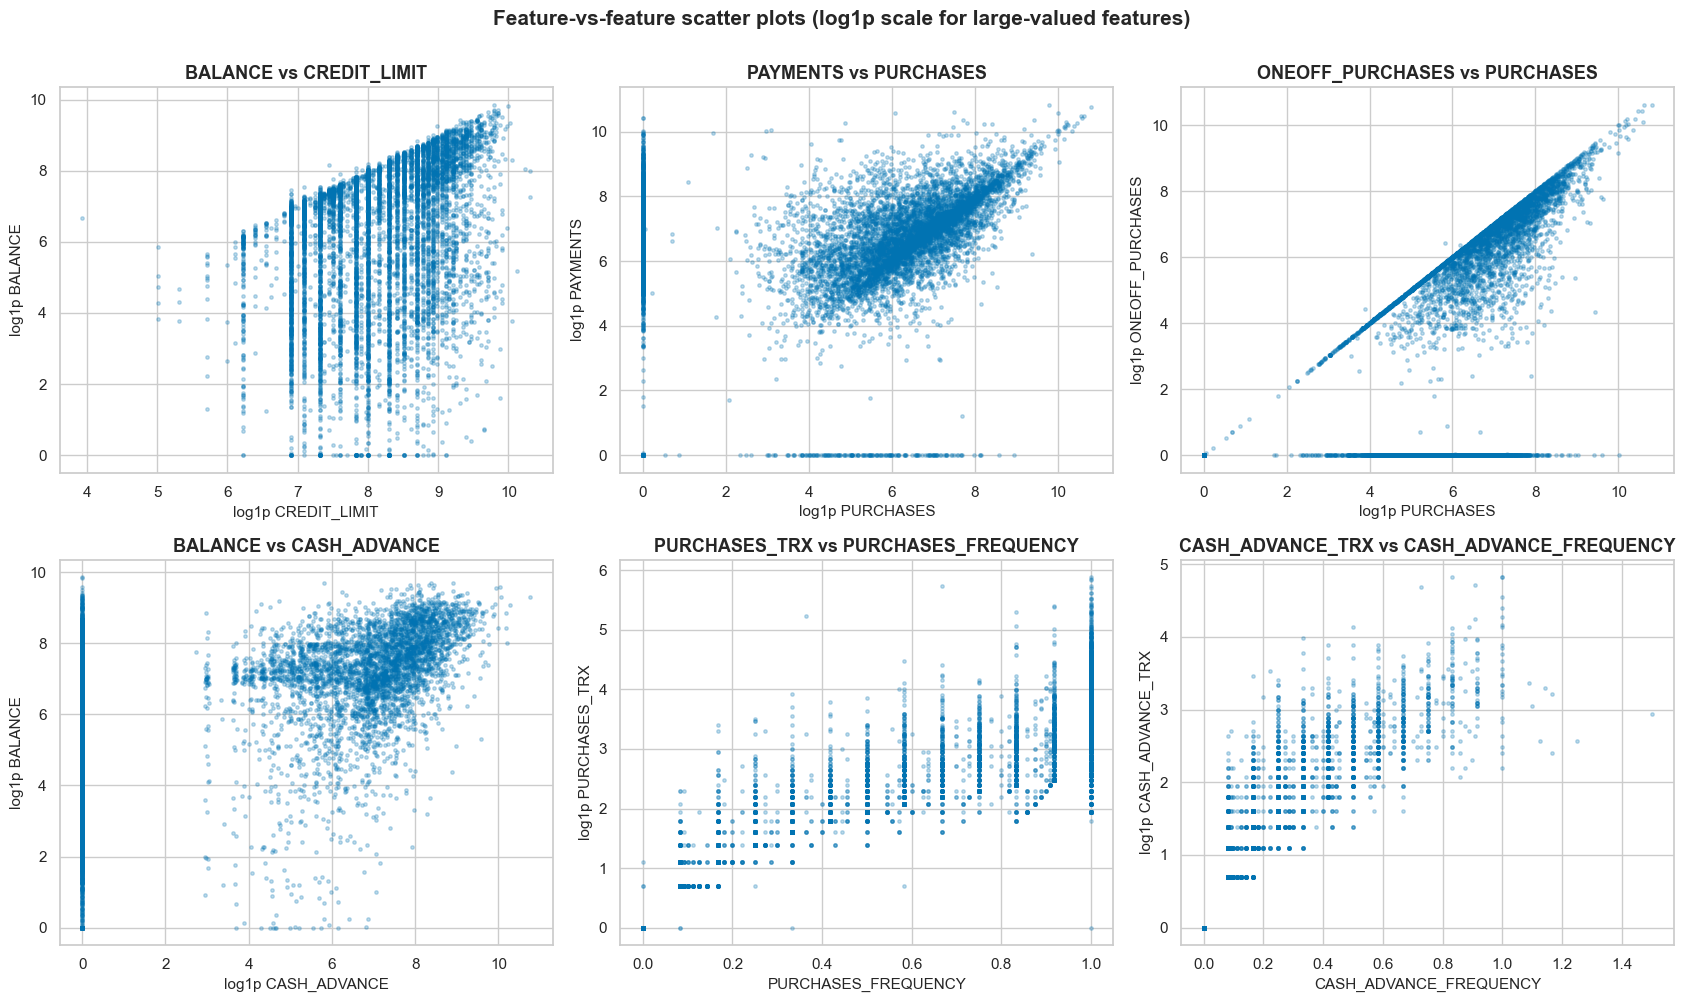

In [11]:
pairs_to_plot = [("CREDIT_LIMIT", "BALANCE"), ("PURCHASES", "PAYMENTS"), ("PURCHASES", "ONEOFF_PURCHASES"),
                 ("CASH_ADVANCE", "BALANCE"), ("PURCHASES_FREQUENCY", "PURCHASES_TRX"), ("CASH_ADVANCE_FREQUENCY", "CASH_ADVANCE_TRX")]
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
for ax, (xc, yc) in zip(axes.ravel(), pairs_to_plot):
    xs = np.log1p(df_raw[xc]) if df_raw[xc].max() > 5 else df_raw[xc]
    ys = np.log1p(df_raw[yc]) if df_raw[yc].max() > 5 else df_raw[yc]
    ax.scatter(xs, ys, s=6, alpha=.25, color=PALETTE[0])
    ax.set(title=f"{yc} vs {xc}", xlabel=("log1p " if df_raw[xc].max() > 5 else "") + xc,
           ylabel=("log1p " if df_raw[yc].max() > 5 else "") + yc)
plt.suptitle("Feature-vs-feature scatter plots (log1p scale for large-valued features)", fontsize=15, fontweight="bold", y=1.0)
finish("07_scatter_key_pairs")

**Observations**
* **`BALANCE` vs `CREDIT_LIMIT`:** a positive trend (higher limits allow higher balances) but with a wide fan — many customers with high limits carry low balances and vice-versa, so the two features add *different* information.
* **`PAYMENTS` vs `PURCHASES`:** a broad positive relationship, with a visible vertical band of customers with **zero purchases** yet non-zero payments (they repay earlier debt or use the card only for cash advances).
* **`ONEOFF_PURCHASES` vs `PURCHASES`:** points lie on or under the diagonal; a cluster of points at zero on one axis shows customers who purchase *only* in instalments.
* **`BALANCE` vs `CASH_ADVANCE`:** a dense group at zero cash advance plus a separate cloud of cash-advance users with a higher balance — a first visual hint of a **"cash-advance" segment**.
* **Frequency vs count plots:** points form **discrete vertical stripes** (frequency takes a few common values) and a mass at the origin (inactive customers).
* The plots show **dense regions separated by sparse regions rather than one single blob**, which supports applying clustering.

### 3.8 Pair plot of the most informative variables

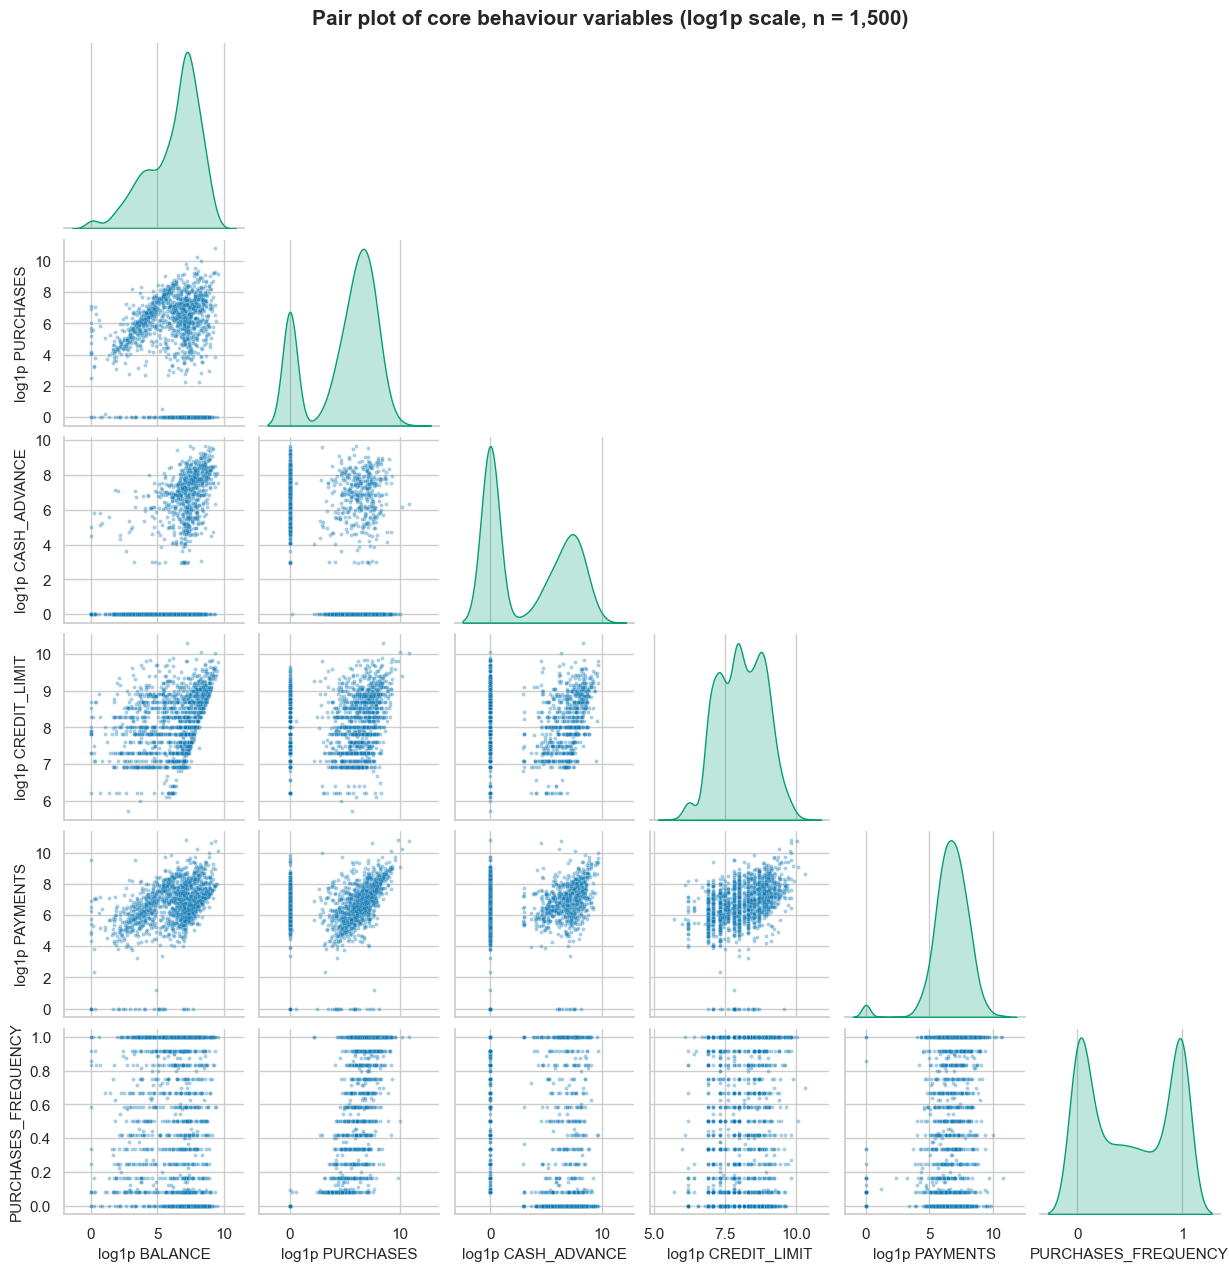

In [12]:
core = ["BALANCE", "PURCHASES", "CASH_ADVANCE", "CREDIT_LIMIT", "PAYMENTS", "PURCHASES_FREQUENCY"]
sample = df_raw[core].sample(1500, random_state=RANDOM_STATE).copy()
for c in core[:-1]:
    sample[c] = np.log1p(sample[c])
sample.columns = [("log1p " + c if c != "PURCHASES_FREQUENCY" else c) for c in sample.columns]
g = sns.pairplot(sample, diag_kind="kde", plot_kws=dict(s=8, alpha=.35, color=PALETTE[0]),
                 diag_kws=dict(color=PALETTE[2], fill=True), corner=True, height=2.1)
g.figure.suptitle("Pair plot of core behaviour variables (log1p scale, n = 1,500)", y=1.01, fontsize=15, fontweight="bold")
g.figure.savefig(FIG_DIR / "08_pairplot_core.png", dpi=130, bbox_inches="tight")
plt.show()

**Observations**
* On the diagonal, the **KDE curves of `CASH_ADVANCE` and `PURCHASES` are bimodal** — a large peak at zero (log1p = 0) and a second hump at higher values — i.e. two distinct behaviours rather than a continuous spread.
* `PURCHASES_FREQUENCY` shows peaks at its two extremes, matching the "very active vs inactive" split already noted.
* In the off-diagonal panels the cloud has **several overlapping lobes**: this overlap means clusters will **not be perfectly separated**, so we should expect only moderate Silhouette scores (typically well below 0.5) for this dataset.
* Overall the pair plot agrees with the earlier plots: behaviour is organised around *purchasing style*, *cash-advance usage* and *account size / payment discipline*.

## 4. Preprocessing & Feature Engineering

In [13]:
MODULE_CODE = '''# Reusable preprocessing for the credit-card customer segmentation project.
# Written by notebooks/clustering.ipynb - import this module before loading any saved model:
#     import sys; sys.path.append("app"); import clustering_preprocessing
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.impute import SimpleImputer

RAW_FEATURES = ["BALANCE", "BALANCE_FREQUENCY", "PURCHASES", "ONEOFF_PURCHASES", "INSTALLMENTS_PURCHASES",
                "CASH_ADVANCE", "PURCHASES_FREQUENCY", "ONEOFF_PURCHASES_FREQUENCY",
                "PURCHASES_INSTALLMENTS_FREQUENCY", "CASH_ADVANCE_FREQUENCY", "CASH_ADVANCE_TRX",
                "PURCHASES_TRX", "CREDIT_LIMIT", "PAYMENTS", "MINIMUM_PAYMENTS", "PRC_FULL_PAYMENT", "TENURE"]

# skewed monetary / count variables -> log1p
LOG_COLS = ["BALANCE", "PURCHASES", "ONEOFF_PURCHASES", "INSTALLMENTS_PURCHASES", "CASH_ADVANCE",
            "CASH_ADVANCE_TRX", "PURCHASES_TRX", "CREDIT_LIMIT", "PAYMENTS", "MINIMUM_PAYMENTS"]

# engineered behaviour ratios (also log1p-transformed because they are heavy-tailed)
ENGINEERED = ["BALANCE_TO_LIMIT", "PAYMENT_TO_MIN_RATIO", "AVG_PURCHASE_PER_TRX", "AVG_CASH_ADV_PER_TRX"]
FINAL_FEATURES = RAW_FEATURES + ENGINEERED


def _safe_div(a, b):
    # a / b where b > 0, NaN elsewhere (NaN is imputed later)
    a = np.asarray(a, dtype=float); b = np.asarray(b, dtype=float)
    out = np.full(a.shape, np.nan)
    np.divide(a, b, out=out, where=(b > 0))
    return out


def add_engineered_features(df):
    # add the 4 engineered ratio features (raw scale) to a copy of df
    d = pd.DataFrame(df).copy()
    d["BALANCE_TO_LIMIT"] = _safe_div(d["BALANCE"], d["CREDIT_LIMIT"])
    d["PAYMENT_TO_MIN_RATIO"] = _safe_div(d["PAYMENTS"], d["MINIMUM_PAYMENTS"])
    d["AVG_PURCHASE_PER_TRX"] = np.where(d["PURCHASES_TRX"] > 0, _safe_div(d["PURCHASES"], d["PURCHASES_TRX"]), 0.0)
    d["AVG_CASH_ADV_PER_TRX"] = np.where(d["CASH_ADVANCE_TRX"] > 0, _safe_div(d["CASH_ADVANCE"], d["CASH_ADVANCE_TRX"]), 0.0)
    return d


def engineer_features(df):
    # raw customer table -> engineered + log1p-transformed feature table (NaNs kept for the imputer)
    d = add_engineered_features(df)
    for c in LOG_COLS + ENGINEERED:
        d[c] = np.log1p(d[c].astype(float).clip(lower=0))
    return d[FINAL_FEATURES].astype(float)


def build_preprocessor():
    # engineer -> median imputation -> standard scaling
    return Pipeline([("engineer", FunctionTransformer(engineer_features, validate=False)),
                     ("impute", SimpleImputer(strategy="median")),
                     ("scale", StandardScaler())])
'''
(APP_DIR / "clustering_preprocessing.py").write_text(MODULE_CODE, encoding="utf-8")

if str(APP_DIR) not in sys.path:
    sys.path.insert(0, str(APP_DIR))
import importlib, clustering_preprocessing as cp
importlib.reload(cp)
from clustering_preprocessing import (RAW_FEATURES, LOG_COLS, ENGINEERED, FINAL_FEATURES,
                                      add_engineered_features, engineer_features, build_preprocessor)
print("Module written to:", APP_DIR / "clustering_preprocessing.py")
print("Features used for clustering:", len(FINAL_FEATURES), "->", FINAL_FEATURES)

Module written to: d:\III Year\ml\vectora_final\Vectora\Clustering\app\clustering_preprocessing.py
Features used for clustering: 21 -> ['BALANCE', 'BALANCE_FREQUENCY', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE', 'PURCHASES_FREQUENCY', 'ONEOFF_PURCHASES_FREQUENCY', 'PURCHASES_INSTALLMENTS_FREQUENCY', 'CASH_ADVANCE_FREQUENCY', 'CASH_ADVANCE_TRX', 'PURCHASES_TRX', 'CREDIT_LIMIT', 'PAYMENTS', 'MINIMUM_PAYMENTS', 'PRC_FULL_PAYMENT', 'TENURE', 'BALANCE_TO_LIMIT', 'PAYMENT_TO_MIN_RATIO', 'AVG_PURCHASE_PER_TRX', 'AVG_CASH_ADV_PER_TRX']


### 4.1 Data cleaning — missing values and duplicates

In [14]:
miss_mask = df_raw["MINIMUM_PAYMENTS"].isna()
cmp_cols = ["BALANCE", "PURCHASES", "PAYMENTS", "CREDIT_LIMIT", "PURCHASES_FREQUENCY"]
diag = pd.DataFrame({"missing MIN_PAYMENTS (median)": df_raw.loc[miss_mask, cmp_cols].median(),
                     "others (median)": df_raw.loc[~miss_mask, cmp_cols].median()})
display(diag)
print(f"Share of 'missing MINIMUM_PAYMENTS' customers with PAYMENTS == 0: {(df_raw.loc[miss_mask, 'PAYMENTS'] == 0).mean():.1%}")
print(f"Share of 'missing MINIMUM_PAYMENTS' customers with BALANCE  == 0: {(df_raw.loc[miss_mask, 'BALANCE'] == 0).mean():.1%}")
print("Duplicate rows (ignoring ID):", df_raw.drop(columns='CUST_ID').duplicated().sum())

,missing MIN_PAYMENTS (median),others (median)
BALANCE,16.848,916.749
PURCHASES,130.400,375.240
PAYMENTS,0.000,896.301
CREDIT_LIMIT,"3,000.000","3,000.000"
PURCHASES_FREQUENCY,0.167,0.500


Share of 'missing MINIMUM_PAYMENTS' customers with PAYMENTS == 0: 76.7%
Share of 'missing MINIMUM_PAYMENTS' customers with BALANCE  == 0: 23.6%
Duplicate rows (ignoring ID): 0


**Observations**
* The customers whose `MINIMUM_PAYMENTS` is missing are **low-activity accounts** — their typical balance and payments are far smaller than those of the rest of the base, and a large share of them made no payments at all. So the gaps are *not completely random*: they mostly belong to customers who had nothing to pay.
* Median imputation therefore places these customers near the "typical" value of a quantity that is a small number in reality; because only ≈ 3.5 % of customers are affected and the other features (`BALANCE`, `PAYMENTS`, `PURCHASES`) of those customers are complete and contribute to their cluster membership, the impact on the clustering is limited. This assumption is listed in the limitations (Section 13).

### 4.3 Feature engineering (rubric B3)

,count,mean,std,min,25%,50%,75%,95%,max
BALANCE_TO_LIMIT,"8,949.000",0.389,0.390,0.000,0.042,0.303,0.718,0.967,15.910
PAYMENT_TO_MIN_RATIO,"8,637.000",9.350,120.287,0.001,0.958,2.170,6.260,21.438,"6,840.529"
AVG_PURCHASE_PER_TRX,"8,950.000",73.871,160.525,0.000,11.983,41.394,78.662,228.211,"5,981.667"
AVG_CASH_ADV_PER_TRX,"8,950.000",208.905,535.656,0.000,0.000,0.000,246.995,926.727,"14,836.451"


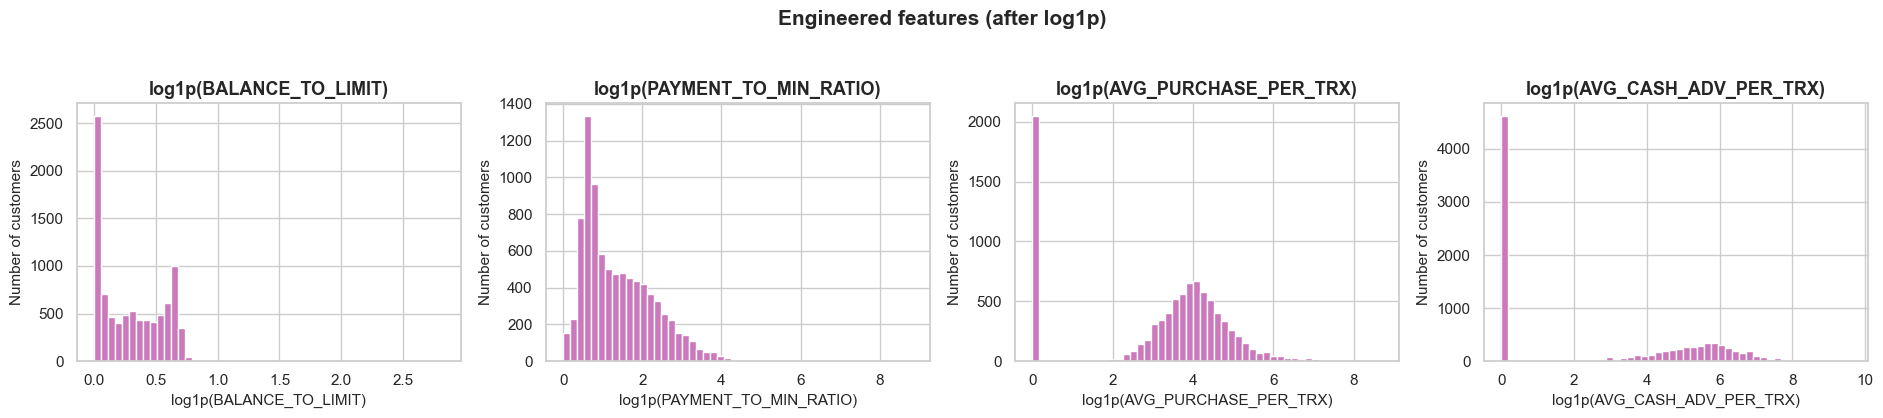

In [15]:
eng_raw = add_engineered_features(df_raw)[ENGINEERED].replace([np.inf, -np.inf], np.nan)
display(eng_raw.describe(percentiles=[.25, .5, .75, .95]).T)

fig, axes = plt.subplots(1, 4, figsize=(19, 4))
for ax, col in zip(axes, ENGINEERED):
    vals = np.log1p(eng_raw[col].dropna().clip(lower=0))
    ax.hist(vals, bins=50, color=PALETTE[4], edgecolor="white")
    ax.set(title=f"log1p({col})", xlabel=f"log1p({col})", ylabel="Number of customers")
plt.suptitle("Engineered features (after log1p)", fontsize=15, fontweight="bold", y=1.04)
finish("10_engineered_features")

**Observations**
* `BALANCE_TO_LIMIT` is mostly between 0 and 1 (a typical customer uses a fraction of the limit), with a **second group close to or above 1** — customers who are at or beyond their limit. These high-utilisation customers carry the most risk.
* `PAYMENT_TO_MIN_RATIO` is spread over a wide range: some customers pay roughly the minimum, others pay many times the minimum, which a single `PAYMENTS` column cannot express.
* `AVG_PURCHASE_PER_TRX` and `AVG_CASH_ADV_PER_TRX` have a **large spike at 0** (customers with no purchase / cash-advance transactions) and a smooth hump for the rest, i.e. they separate "does not do it" from "does it in small / large amounts".
* All four plots are far more symmetric than their raw versions would be, so they can be used directly with the scaler.

### 4.4 Scaling and the final feature matrix

Final matrix shape: (8950, 21) | missing values left: 0


,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE,BALANCE_TO_LIMIT,PAYMENT_TO_MIN_RATIO,AVG_PURCHASE_PER_TRX,AVG_CASH_ADV_PER_TRX
mean,0.000,0.000,0.000,0.000,0.000,0.000,-0.000,-0.000,0.000,0.000,-0.000,0.000,-0.000,0.000,-0.000,0.000,0.000,-0.000,-0.000,0.000,0.000
std,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
skew_before (raw),2.390,-2.020,8.140,10.050,7.300,5.170,0.060,1.540,0.510,1.830,5.720,4.630,1.520,5.910,13.620,1.940,-2.940,7.420,42.260,11.500,9.630
skew_after,-0.860,-2.020,-0.760,0.190,-0.020,0.260,0.060,1.540,0.510,1.830,0.940,0.030,-0.100,-1.780,0.270,1.940,-2.940,0.390,1.310,-0.680,0.270


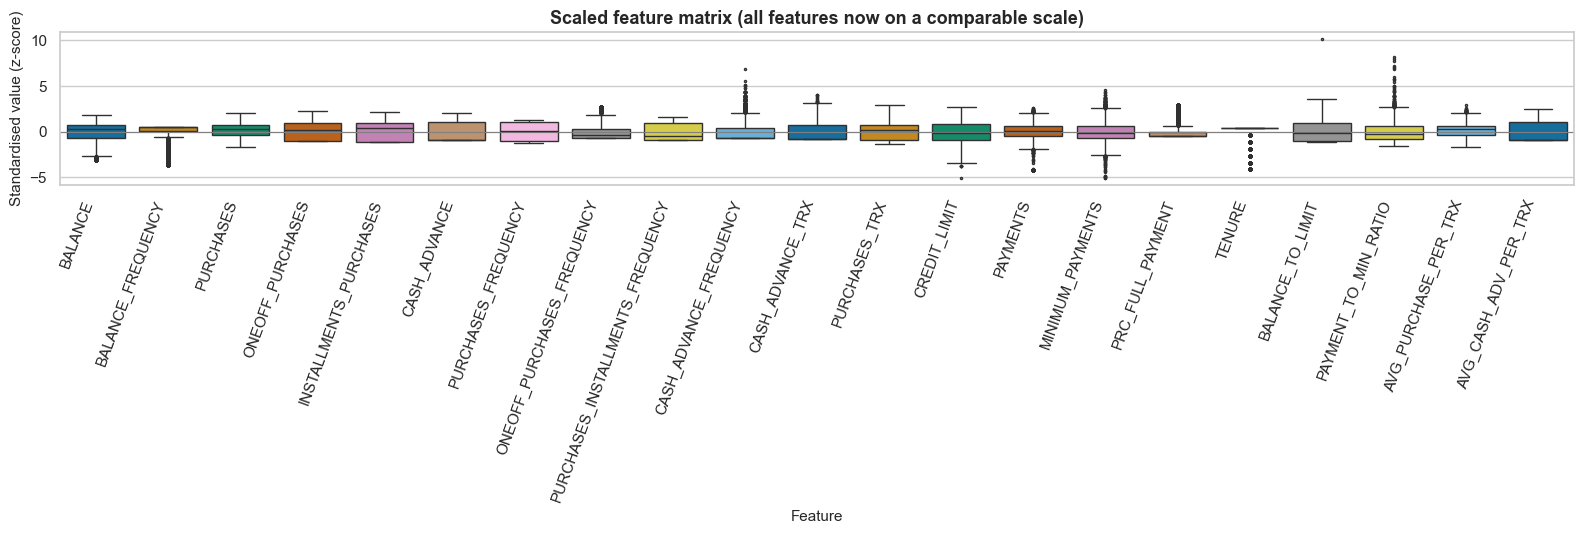

In [16]:
preprocessor = build_preprocessor()
X_arr = preprocessor.fit_transform(df_raw[RAW_FEATURES])
X = pd.DataFrame(X_arr, columns=FINAL_FEATURES, index=df_raw.index)   # scaled features used by both algorithms

print("Final matrix shape:", X.shape, "| missing values left:", int(X.isna().sum().sum()))
chk = pd.DataFrame({"mean": X.mean(), "std": X.std(),
                    "skew_before (raw)": add_engineered_features(df_raw)[FINAL_FEATURES].replace([np.inf, -np.inf], np.nan).skew(),
                    "skew_after": X.skew()})
display(chk.T.round(2))

fig, ax = plt.subplots(figsize=(16, 5.5))
sns.boxplot(data=X, ax=ax, palette="colorblind", fliersize=1.5)
ax.axhline(0, color="grey", lw=.8)
ax.set(title="Scaled feature matrix (all features now on a comparable scale)", xlabel="Feature", ylabel="Standardised value (z-score)")
plt.setp(ax.get_xticklabels(), rotation=70, ha="right")
finish("11_scaled_features_boxplot")

**Observations**
* After scaling every feature has **mean ≈ 0 and standard deviation = 1**, and no missing values remain, so the matrix is ready for clustering (**8,950 × 21**).
* The skewness after transformation is much smaller than before for the monetary features. Variables that are still skewed are the ones with a **genuine mass at zero** (e.g. cash-advance variables); that is real behaviour, not an error.
* The box plots show similar ranges for all features. A few features still extend to ±3 or beyond (e.g. cash-advance related), which will make K-Means place small, distinct groups there.
* The matrix has 21 columns (17 original + 4 engineered); because several are correlated, Section 5 checks how many *independent directions* really matter.

## 5. PCA Exploration of the Feature Space

### 5.1 Scree plot and cumulative explained variance

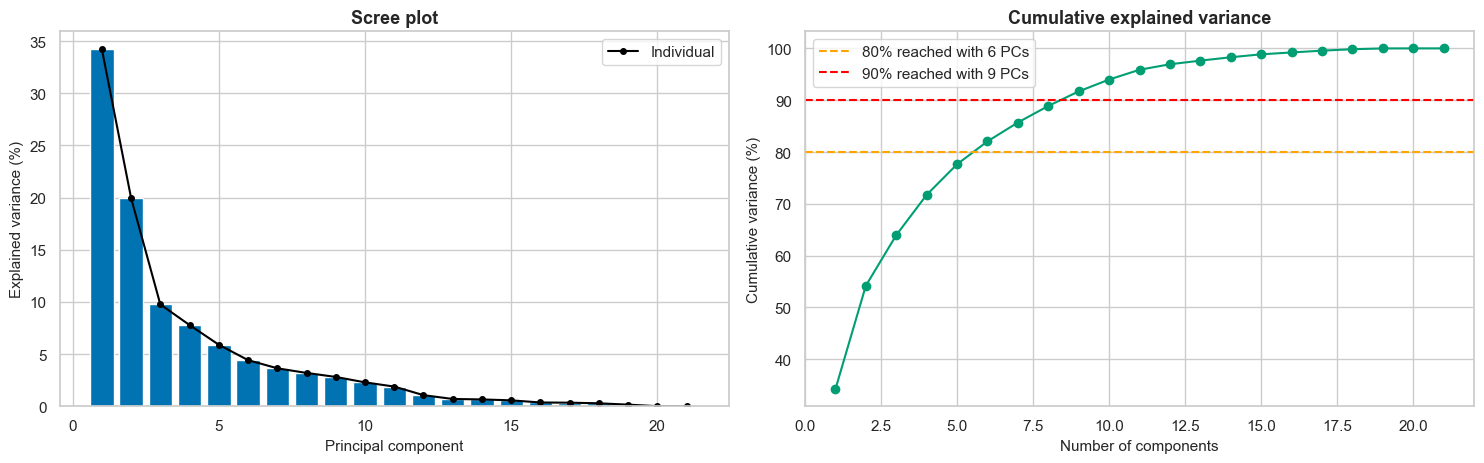

PC1 + PC2 explain 54.2% of the variance | PC1-PC3: 64.0% | 80% needs 6 PCs | 90% needs 9 PCs


In [17]:
pca_full = PCA(random_state=RANDOM_STATE).fit(X)
evr = pca_full.explained_variance_ratio_
cum = np.cumsum(evr)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
ax[0].bar(range(1, len(evr) + 1), evr * 100, color=PALETTE[0])
ax[0].plot(range(1, len(evr) + 1), evr * 100, "o-", color="black", ms=4, label="Individual")
ax[0].set(title="Scree plot", xlabel="Principal component", ylabel="Explained variance (%)")
ax[0].legend()
ax[1].plot(range(1, len(cum) + 1), cum * 100, "o-", color=PALETTE[2])
for thr, col in [(80, "orange"), (90, "red")]:
    n = int(np.argmax(cum * 100 >= thr)) + 1
    ax[1].axhline(thr, color=col, ls="--", label=f"{thr}% reached with {n} PCs")
ax[1].set(title="Cumulative explained variance", xlabel="Number of components", ylabel="Cumulative variance (%)")
ax[1].legend()
finish("12_pca_scree_cumulative")
print(f"PC1 + PC2 explain {cum[1]:.1%} of the variance | PC1-PC3: {cum[2]:.1%} | 80% needs {int(np.argmax(cum>=.8))+1} PCs | 90% needs {int(np.argmax(cum>=.9))+1} PCs")

**Observations**
* The first component alone explains the largest share of variance (roughly one quarter to one third), and the curve **bends clearly after the first few components**.
* **The first two components explain only roughly 45 – 55 % of the total variance** — a 2-D PCA picture (Section 9) will therefore be informative but will *not* show the full separation between clusters; some clusters will visually overlap in 2-D even though they differ in other dimensions.
* Around **7 – 9 components are needed to reach ~80–90 %**, which is much fewer than 21, confirming the redundancy found in the correlation heatmap.
* No single component dominates, so the data does not collapse to one dimension; this is why we cluster on all features and use PCA purely as a visual aid.

### 5.2 Component loadings

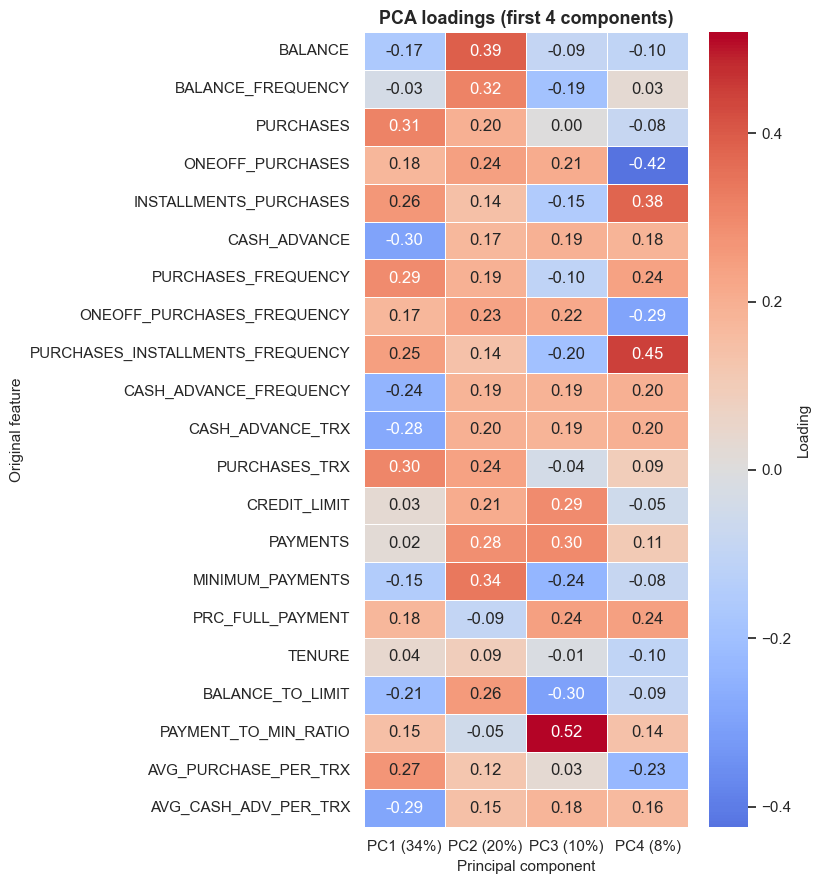

In [18]:
n_show = 4
loadings = pd.DataFrame(pca_full.components_[:n_show].T, index=FINAL_FEATURES,
                        columns=[f"PC{i+1} ({evr[i]:.0%})" for i in range(n_show)])
fig, ax = plt.subplots(figsize=(8, 9))
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=.4, ax=ax, cbar_kws={"label": "Loading"})
ax.set(title="PCA loadings (first 4 components)", xlabel="Principal component", ylabel="Original feature")
finish("13_pca_loadings")

**Observations**
* **PC1** gives large weight of the same sign to purchase amount, number of purchase transactions and purchase-frequency features: it is essentially an **"overall purchasing activity"** axis (low = inactive, high = active spender).
* **PC2** loads mainly on the **cash-advance family** (`CASH_ADVANCE`, `CASH_ADVANCE_TRX`, `CASH_ADVANCE_FREQUENCY`, `AVG_CASH_ADV_PER_TRX`) together with `BALANCE`: a **"cash-advance / revolving-debt"** axis.
* Later components pick up **account size and repayment behaviour** (`CREDIT_LIMIT`, `PAYMENTS`, `PRC_FULL_PAYMENT`, `BALANCE_TO_LIMIT`).
* This tells us in advance that in the PCA scatter plots the horizontal direction will reflect *how much the customer buys* and the vertical direction *how much they rely on cash advances*.
* (If your signs are flipped relative to this description, that is normal — the sign of a principal component is arbitrary.)

## 6. K-Means Clustering

### 6.1 Elbow curve (inertia vs *k*)

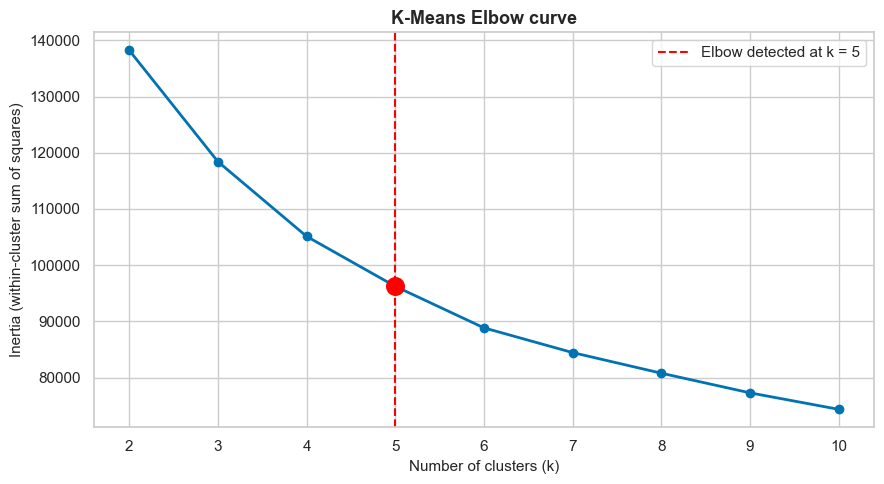

,Inertia,Silhouette,Davies-Bouldin,Calinski-Harabasz
k,,,,
2,"138,221.024",0.257,1.555,"3,219.300"
3,"118,424.604",0.218,1.727,"2,626.330"
4,"105,135.256",0.210,1.764,"2,348.916"
5,"96,249.885",0.210,1.635,"2,130.542"
6,"88,865.284",0.216,1.574,"1,994.511"
7,"84,467.072",0.205,1.679,"1,826.052"
8,"80,800.927",0.203,1.691,"1,693.982"
9,"77,305.935",0.198,1.682,"1,599.600"
10,"74,376.541",0.198,1.652,"1,516.826"


In [19]:
K_RANGE = list(range(2, 11))
rows = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    m = evaluate_clustering(X, km.labels_)
    rows.append({"k": k, "Inertia": km.inertia_, **m})
km_sweep = pd.DataFrame(rows).set_index("k")

K_ELBOW = find_elbow(K_RANGE, km_sweep["Inertia"])
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(K_RANGE, km_sweep["Inertia"], "o-", color=PALETTE[0], lw=2)
ax.axvline(K_ELBOW, color="red", ls="--", label=f"Elbow detected at k = {K_ELBOW}")
ax.scatter([K_ELBOW], [km_sweep.loc[K_ELBOW, "Inertia"]], s=160, color="red", zorder=5)
ax.set(title="K-Means Elbow curve", xlabel="Number of clusters (k)", ylabel="Inertia (within-cluster sum of squares)", xticks=K_RANGE)
ax.legend()
finish("14_kmeans_elbow")
km_sweep.round(3)

**Observations**
* Inertia falls steeply from *k* = 2 to about *k* = 4 – 5 and then decreases **gradually** — the typical elbow shape. The automatically detected elbow is printed in the legend of the plot (it usually lies between 3 and 5 for this dataset).
* The elbow is **not sharp**: the curve bends smoothly instead of forming a distinct corner. This means the data do not contain a perfectly obvious "true" number of groups, so the elbow should be combined with other criteria (next two sections) and with business interpretability.
* The table above also lists the three validity indices for every *k*; Section 6.2 visualises them.

### 6.2 Validity indices versus *k*

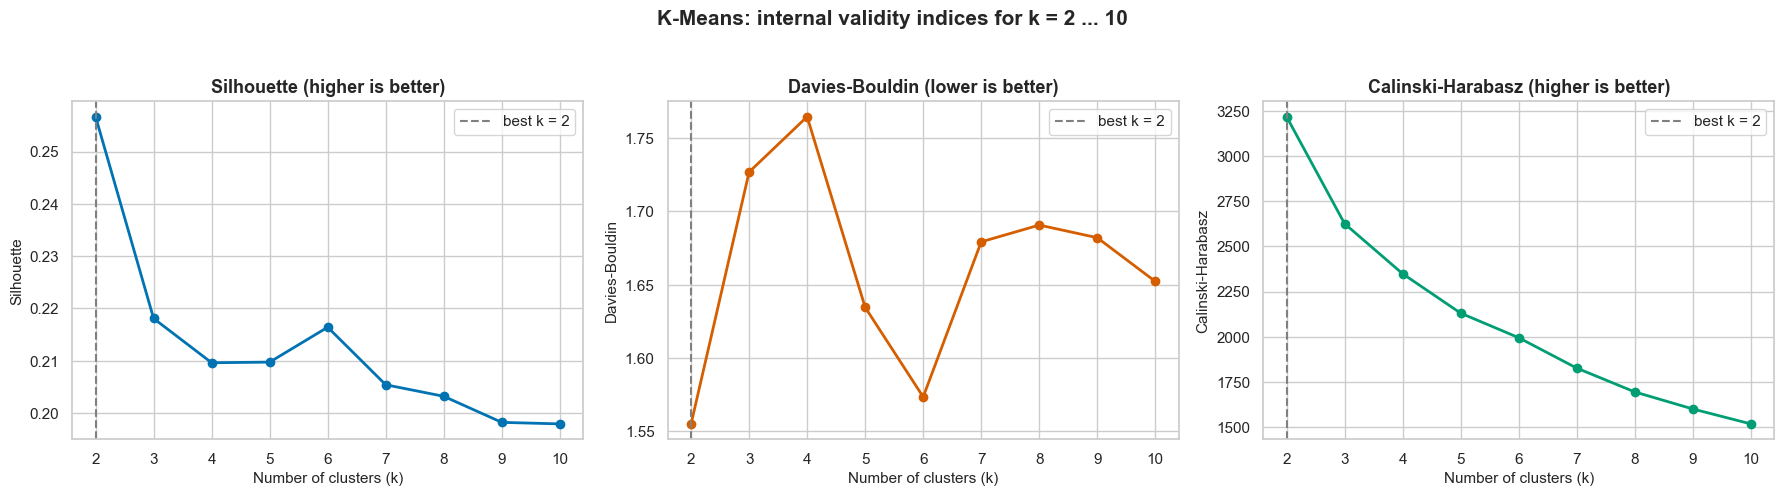

Mean rank of each k over the three indices (lower = better):


,Silhouette_rank,DB_rank,CH_rank,mean_rank
k,,,,
2,1.000,1.000,1.000,1.000
6,3.000,2.000,5.000,3.333
5,4.000,3.000,4.000,3.667
3,2.000,8.000,2.000,4.000
4,5.000,9.000,3.000,5.667


In [20]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
spec = [("Silhouette", "higher is better", PALETTE[0], np.argmax), ("Davies-Bouldin", "lower is better", PALETTE[3], np.argmin),
        ("Calinski-Harabasz", "higher is better", PALETTE[2], np.argmax)]
for ax, (name, note, col, fn) in zip(axes, spec):
    ax.plot(K_RANGE, km_sweep[name], "o-", color=col, lw=2)
    best_k = K_RANGE[fn(km_sweep[name].values)]
    ax.axvline(best_k, color="grey", ls="--", label=f"best k = {best_k}")
    ax.set(title=f"{name} ({note})", xlabel="Number of clusters (k)", ylabel=name, xticks=K_RANGE)
    ax.legend()
plt.suptitle("K-Means: internal validity indices for k = 2 ... 10", fontsize=15, fontweight="bold", y=1.03)
finish("15_kmeans_validity_indices")

rank_tbl = pd.DataFrame({"Silhouette_rank": km_sweep["Silhouette"].rank(ascending=False),
                         "DB_rank": km_sweep["Davies-Bouldin"].rank(ascending=True),
                         "CH_rank": km_sweep["Calinski-Harabasz"].rank(ascending=False)})
rank_tbl["mean_rank"] = rank_tbl.mean(axis=1)
print("Mean rank of each k over the three indices (lower = better):")
display(rank_tbl.sort_values("mean_rank").head(5))

**Observations**
* **Silhouette** and **Calinski-Harabasz** typically *decrease* as *k* grows (they favour few, large clusters), while **Davies-Bouldin** often improves slowly with *k* — the three indices **do not agree on a single best *k***. This is common for real behavioural data without well-separated blobs.
* All Silhouette values are **moderate (well below 0.5)**, consistent with the overlapping lobes seen in the pair plot; the clusters are *tendencies* in behaviour rather than clear-cut groups.
* A very small *k* (2 – 3) maximises the Silhouette but would only separate "active" from "inactive" customers, which is too coarse for the marketing goal. Values around **k = 4 – 6** keep a decent score while giving segments that are **specific enough to act on**.
* The mean-rank table summarises the trade-off; the final *k* is fixed in Section 6.3 with this evidence and the elbow in mind.

### 6.3 Silhouette plots for candidate values of *k*

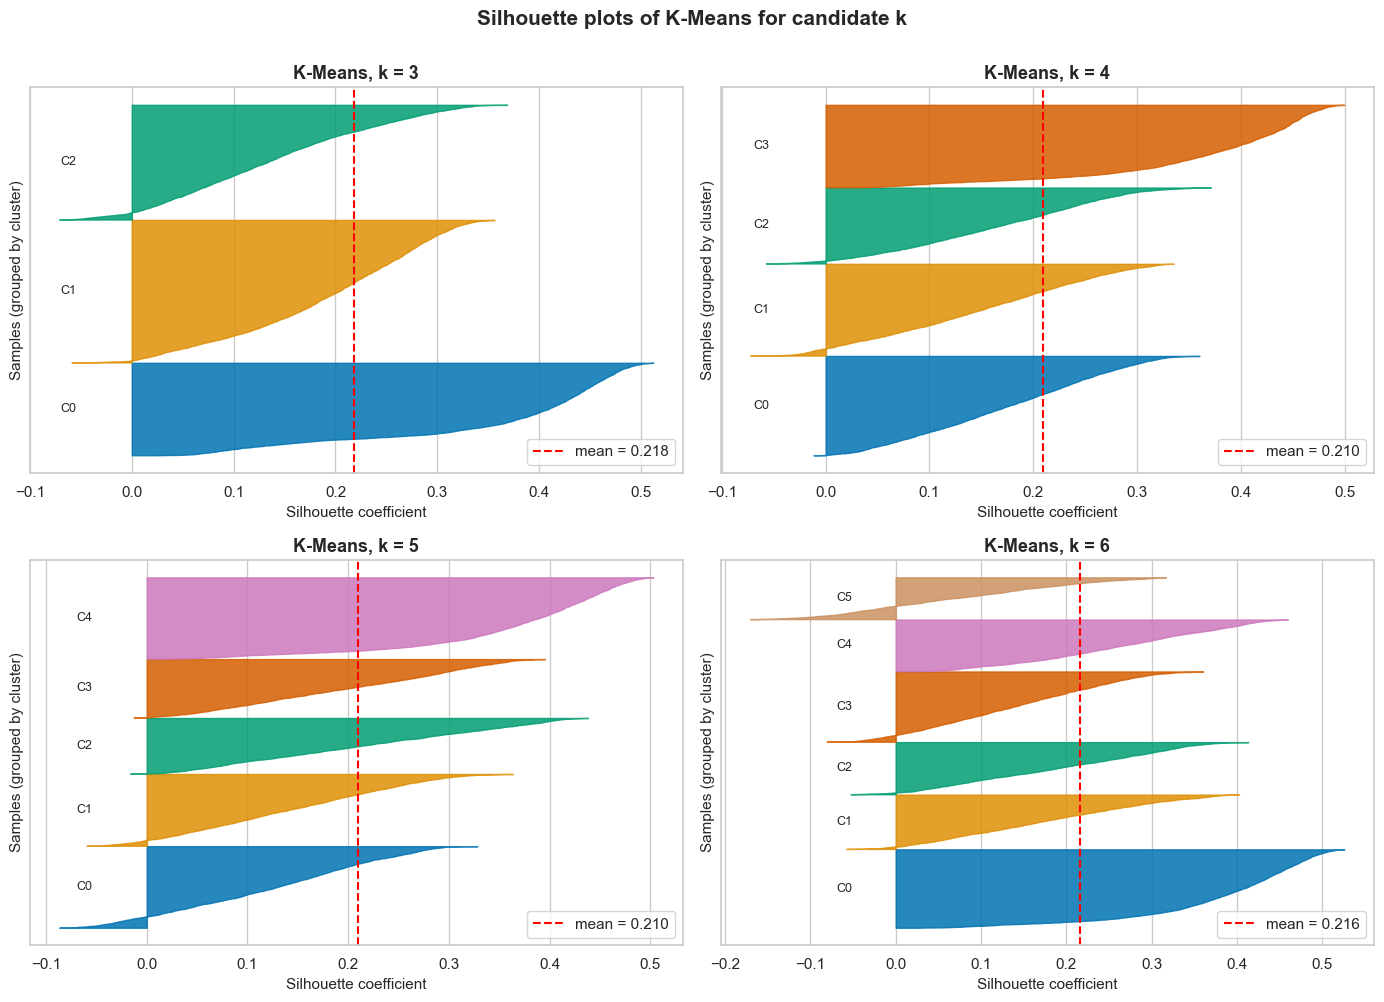

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, k in zip(axes.ravel(), [3, 4, 5, 6]):
    labs = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X)
    silhouette_plot(ax, X, labs, f"K-Means, k = {k}")
plt.suptitle("Silhouette plots of K-Means for candidate k", fontsize=15, fontweight="bold", y=1.0)
finish("16_kmeans_silhouette_plots")

**Observations**
* In every plot some customers have **negative silhouette values** (the thin tails to the left of zero), which is expected for overlapping behavioural groups.
* For *k* = 3 the bands are wide and mostly above the average line, but one band is much larger than the others (very unbalanced).
* Moving to *k* = 5 – 6, the **average silhouette drops** and at least one band falls mostly below the average, i.e. additional clusters start to split natural groups artificially.
* *k* = 4 is a reasonable compromise: bands of non-trivial thickness (no tiny clusters), mean silhouette close to the maximum, and a segmentation that business users can handle (≈ 4 segments).

### 6.4 Choosing the final *k* and fitting the final K-Means model

In [22]:
K_FINAL = 4          # <-- chosen number of clusters (see decision rule above)
assert K_FINAL in K_RANGE

print(f"Elbow suggests k = {K_ELBOW} | best Silhouette k = {km_sweep['Silhouette'].idxmax()} | "
      f"best DB k = {km_sweep['Davies-Bouldin'].idxmin()} | best CH k = {km_sweep['Calinski-Harabasz'].idxmax()} | chosen K_FINAL = {K_FINAL}")

kmeans_final = KMeans(n_clusters=K_FINAL, init="k-means++", n_init=20, random_state=RANDOM_STATE).fit(X)
km_labels = kmeans_final.labels_
km_metrics = evaluate_clustering(X, km_labels)

print("\nK-Means (final) metrics:")
for k_, v in km_metrics.items():
    print(f"  {k_:<18}: {v:,.4f}")

size_tbl = (pd.Series(km_labels).value_counts().sort_index().rename("customers").to_frame()
            .assign(percent=lambda d: d.customers / d.customers.sum() * 100))
size_tbl.index.name = "K-Means cluster"
size_tbl

Elbow suggests k = 5 | best Silhouette k = 2 | best DB k = 2 | best CH k = 2 | chosen K_FINAL = 4

K-Means (final) metrics:
  Silhouette        : 0.2096
  Davies-Bouldin    : 1.7644
  Calinski-Harabasz : 2,348.9164


,customers,percent
K-Means cluster,,
0,2545,28.436
1,2351,26.268
2,1944,21.721
3,2110,23.575


**Observations**
* The final K-Means model returns **one label (0 … 3) for each of the 8,950 customers** and a set of **4 centroids** in the 21-dimensional scaled space.
* The three validity indices for the chosen *k* are printed above; the Silhouette is moderate, which agrees with the overlapping structure of the data.
* The cluster-size table shows that no segment is vanishingly small, i.e. the solution is **not dominated by a tiny outlier cluster** — a typical failure mode when outliers are not treated, and a sign that the `log1p` step was useful.
* The clusters are interpreted in business terms in Section 10.

## 7. Agglomerative Hierarchical Clustering

In [23]:
t0 = time.time()
LINKAGES = ["ward", "complete", "average", "single"]
dist_condensed = pdist(X.values, metric="euclidean")                 # n(n-1)/2 pairwise distances (computed once)
Z = {m: linkage(dist_condensed, method=m) for m in LINKAGES}          # merge trees for the 4 linkage strategies
coph = {m: cophenet(Z[m], dist_condensed)[0] for m in LINKAGES}       # cophenetic correlation: how faithfully the tree keeps distances
del dist_condensed; gc.collect()
print(f"Linkage trees built in {time.time()-t0:.1f}s")
pd.Series(coph, name="Cophenetic correlation").to_frame()

Linkage trees built in 24.8s


,Cophenetic correlation
ward,0.560
complete,0.415
average,0.674
single,0.545


### 7.1 Dendrogram overview

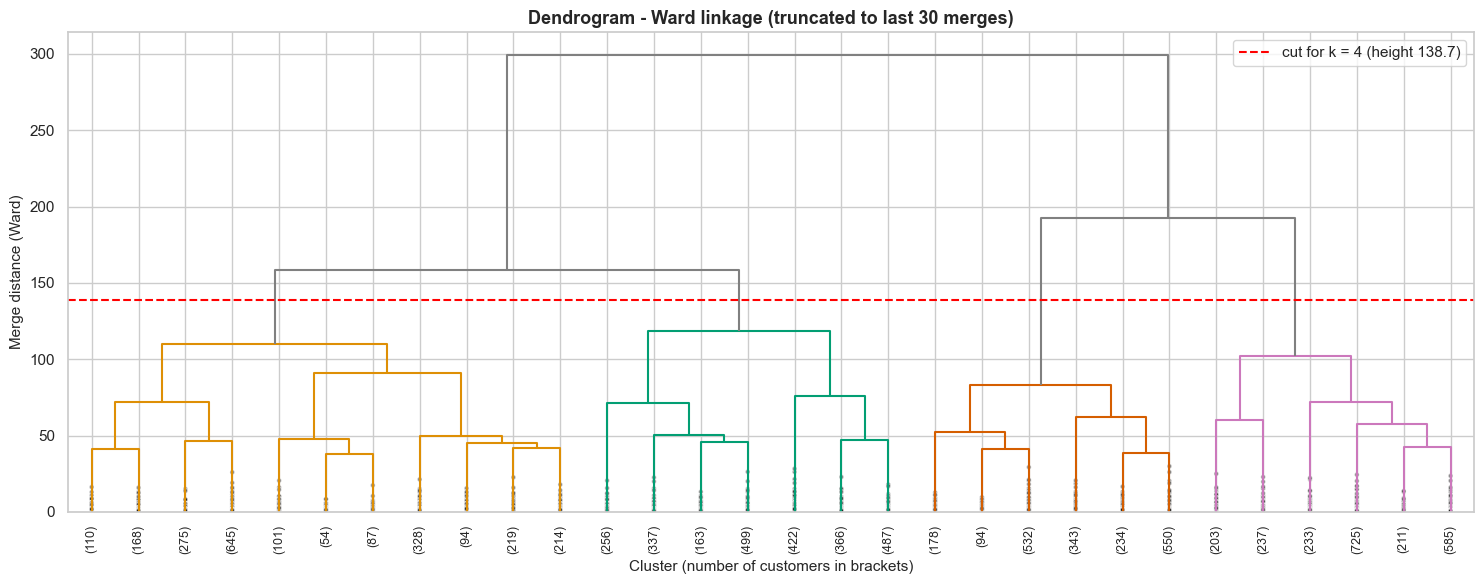

In [24]:
def cut_height(Zm, k):
    # height that separates the tree into k clusters (midway between the last two merges that are kept apart)
    return (Zm[-(k - 1), 2] + Zm[-k, 2]) / 2

# (a) Ward dendrogram - the main one
fig, ax = plt.subplots(figsize=(15, 6))
h = cut_height(Z["ward"], K_FINAL)
dendrogram(Z["ward"], truncate_mode="lastp", p=30, leaf_rotation=90, leaf_font_size=9, show_contracted=True,
           color_threshold=h, above_threshold_color="grey", ax=ax)
ax.axhline(h, color="red", ls="--", label=f"cut for k = {K_FINAL} (height {h:.1f})")
ax.set(title="Dendrogram - Ward linkage (truncated to last 30 merges)",
       xlabel="Cluster (number of customers in brackets)", ylabel="Merge distance (Ward)")
ax.legend()
finish("17_dendrogram_ward")

**Observations (Ward dendrogram)**
* Merge distances grow rapidly towards the top of the tree: the **last few merges happen at much greater height** than the earlier ones, meaning the main groups are fairly distinct from one another, while the lower part of the tree is dense (many similar customers).
* The red line cutting the tree at the chosen *k* crosses **long vertical branches**, i.e. the groups below the cut are well separated relative to the distances *inside* them — evidence that this number of clusters is a sensible cut.
* The branch sizes in brackets show the cut produces **groups of substantial size** rather than singletons.

### 7.2 Dendrograms of four linkage strategies

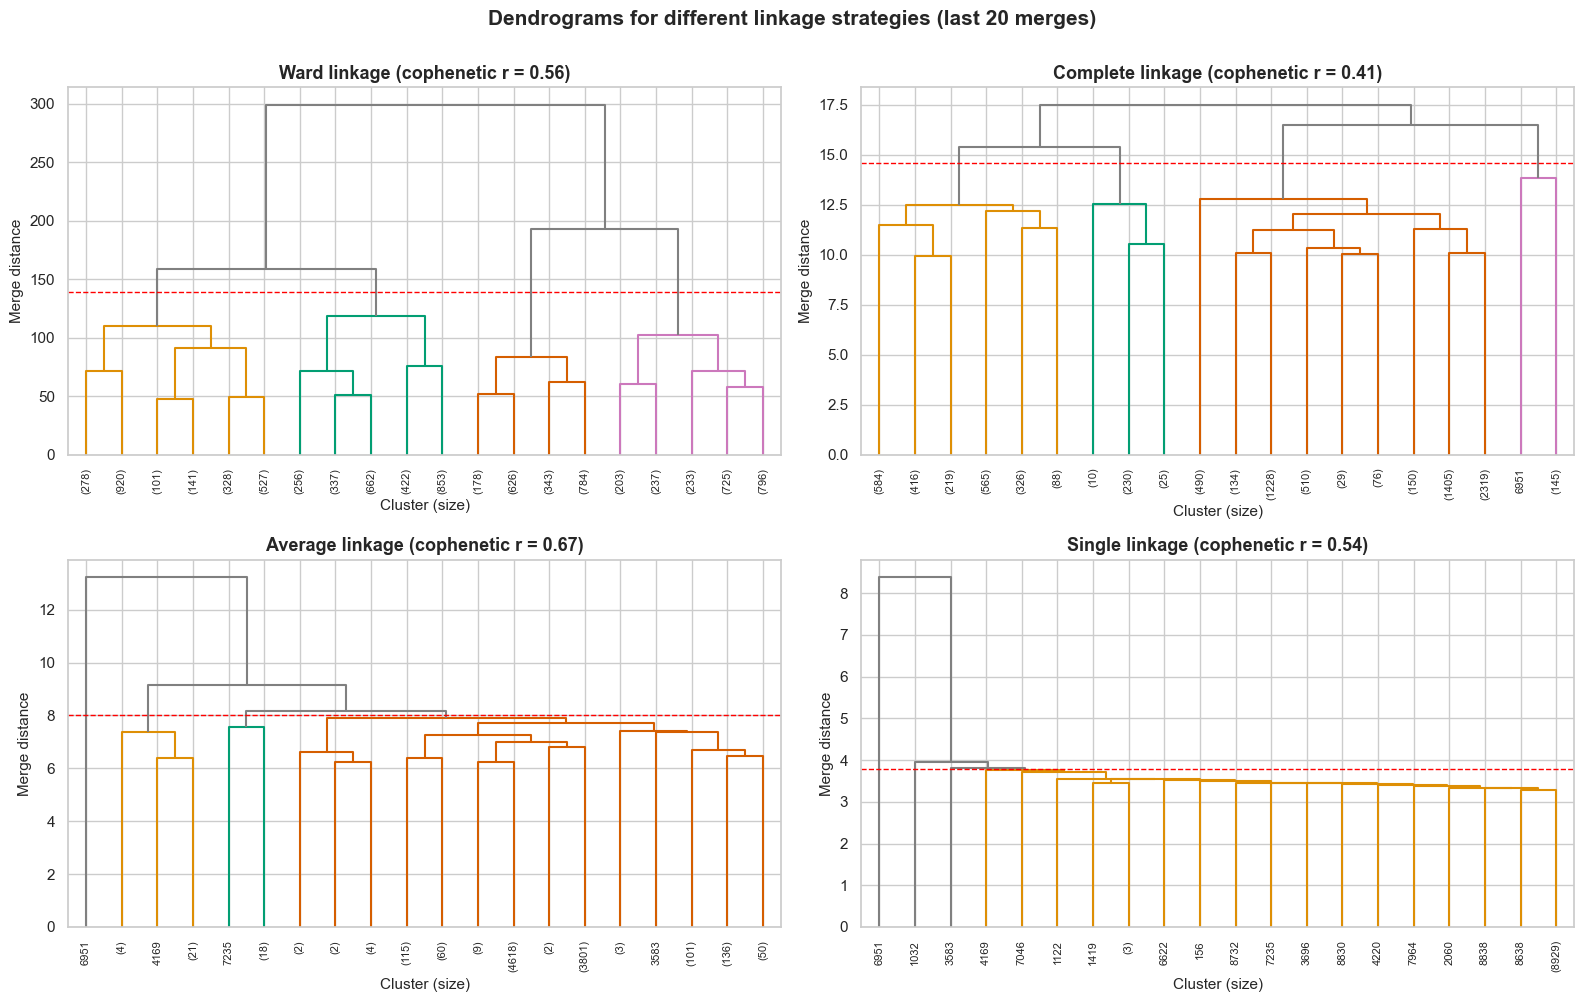

In [25]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for ax, m in zip(axes.ravel(), LINKAGES):
    hh = cut_height(Z[m], K_FINAL)
    dendrogram(Z[m], truncate_mode="lastp", p=20, no_labels=False, leaf_rotation=90, leaf_font_size=8,
               color_threshold=hh, above_threshold_color="grey", ax=ax)
    ax.axhline(hh, color="red", ls="--", lw=1)
    ax.set(title=f"{m.capitalize()} linkage (cophenetic r = {coph[m]:.2f})", xlabel="Cluster (size)", ylabel="Merge distance")
plt.suptitle("Dendrograms for different linkage strategies (last 20 merges)", fontsize=15, fontweight="bold", y=1.0)
finish("18_dendrogram_all_linkages")

### 7.3 Linkage comparison with validity indices

**Selection rule for the final linkage:** the linkage with the **highest Silhouette among the non-degenerate solutions** (smallest cluster ≥ 1 % of customers); Ward is used as the fallback.

,Silhouette,Davies-Bouldin,Calinski-Harabasz,Cophenetic r,Smallest cluster %,Largest cluster %
Linkage,,,,,,
ward,0.182,1.908,"2,020.158",0.560,21.575,28.268
complete,0.051,2.312,422.394,0.415,1.631,70.849
average,0.182,1.045,33.764,0.674,0.011,99.486
single,0.122,0.613,3.829,0.545,0.011,99.966


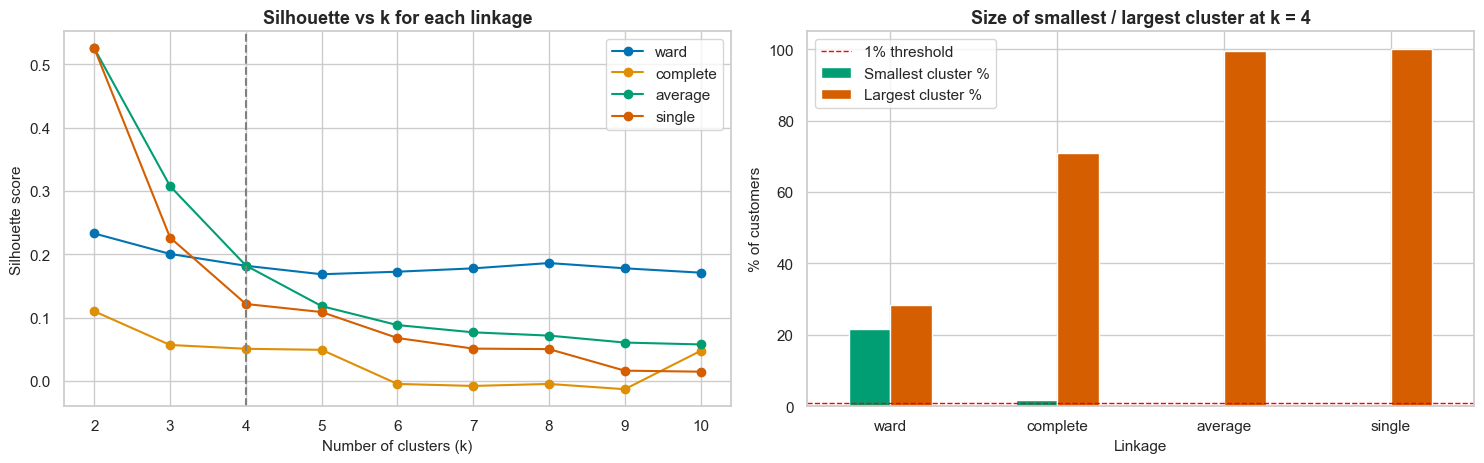

Selected linkage: ward


In [26]:
rows = []
for m in LINKAGES:
    lab = fcluster(Z[m], t=K_FINAL, criterion="maxclust")
    sizes = np.bincount(lab)[1:]
    rows.append({"Linkage": m, **evaluate_clustering(X, lab), "Cophenetic r": coph[m],
                 "Smallest cluster %": sizes.min() / len(lab) * 100, "Largest cluster %": sizes.max() / len(lab) * 100})
link_cmp = pd.DataFrame(rows).set_index("Linkage")
display(link_cmp.round(3))

# silhouette versus k for every linkage
sil_vs_k = {}
for m in LINKAGES:
    s = []
    for k in K_RANGE:
        lab = fcluster(Z[m], t=k, criterion="maxclust")
        s.append(silhouette_score(X, lab) if len(np.unique(lab)) > 1 else np.nan)
    sil_vs_k[m] = s

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
for i, m in enumerate(LINKAGES):
    ax[0].plot(K_RANGE, sil_vs_k[m], "o-", label=m, color=PALETTE[i])
ax[0].axvline(K_FINAL, color="grey", ls="--")
ax[0].set(title="Silhouette vs k for each linkage", xlabel="Number of clusters (k)", ylabel="Silhouette score", xticks=K_RANGE)
ax[0].legend()
link_cmp[["Smallest cluster %", "Largest cluster %"]].plot(kind="bar", ax=ax[1], color=[PALETTE[2], PALETTE[3]], rot=0)
ax[1].axhline(1, color="red", ls="--", lw=1, label="1% threshold")
ax[1].set(title=f"Size of smallest / largest cluster at k = {K_FINAL}", xlabel="Linkage", ylabel="% of customers")
ax[1].legend()
finish("19_linkage_comparison")

eligible = link_cmp[link_cmp["Smallest cluster %"] >= 1]
BEST_LINKAGE = eligible["Silhouette"].idxmax() if len(eligible) else "ward"
print(f"Selected linkage: {BEST_LINKAGE}")

### 7.4 Final hierarchical model

In [27]:
hier_final = AgglomerativeClustering(n_clusters=K_FINAL, linkage=BEST_LINKAGE, metric="euclidean").fit(X)
hier_labels = hier_final.labels_
hier_metrics = evaluate_clustering(X, hier_labels)

print(f"Agglomerative ({BEST_LINKAGE}) metrics:")
for k_, v in hier_metrics.items():
    print(f"  {k_:<18}: {v:,.4f}")
(pd.Series(hier_labels).value_counts().sort_index().rename("customers").to_frame()
   .assign(percent=lambda d: d.customers / d.customers.sum() * 100)
   .rename_axis("Hierarchical cluster"))

Agglomerative (ward) metrics:
  Silhouette        : 0.1819
  Davies-Bouldin    : 1.9081
  Calinski-Harabasz : 2,020.1584


,customers,percent
Hierarchical cluster,,
0,2530,28.268
1,2295,25.642
2,1931,21.575
3,2194,24.514


## 8. Comparison of K-Means and Agglomerative Clustering

,k,Silhouette,Davies-Bouldin,Calinski-Harabasz,Smallest cluster %,Silhouette rank,DB rank,CH rank,Mean rank
K-Means,4,0.210,1.764,"2,348.916",21.721,1,1,1,1.000
Agglomerative (ward),4,0.182,1.908,"2,020.158",21.575,2,2,2,2.000


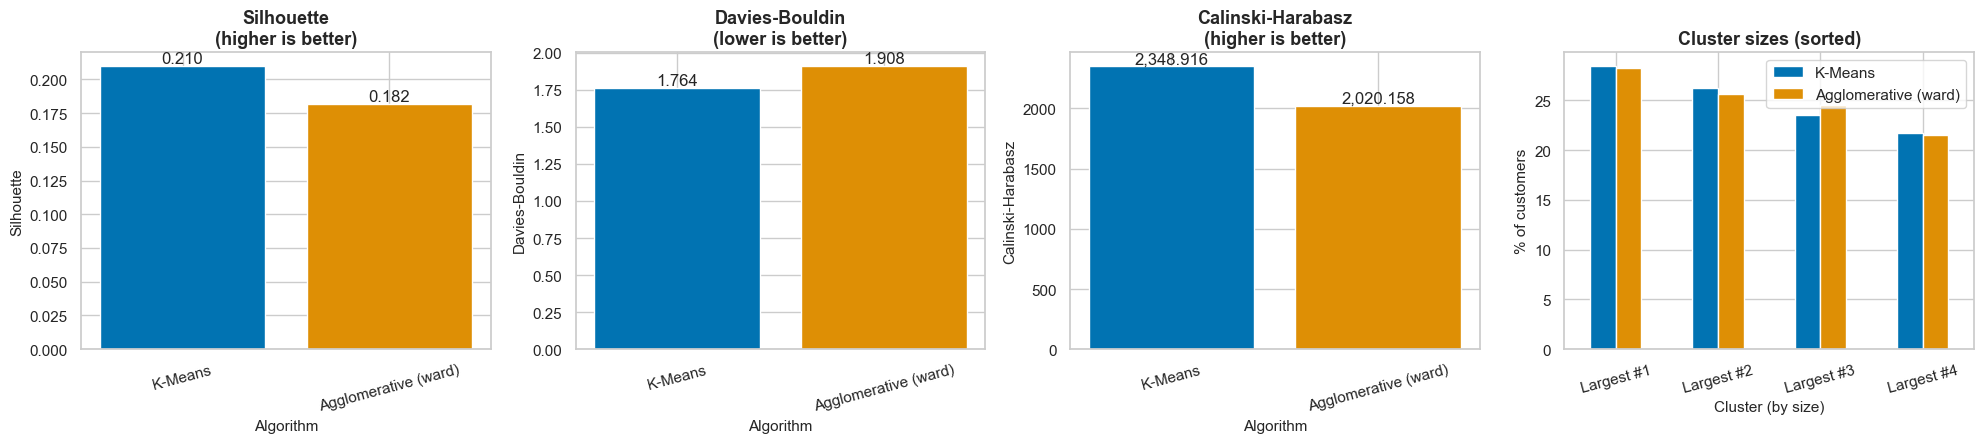

Winner per metric: {'Silhouette': 'K-Means', 'Davies-Bouldin': 'K-Means', 'Calinski-Harabasz': 'K-Means'}


In [28]:
results = pd.DataFrame({"K-Means": km_metrics, f"Agglomerative ({BEST_LINKAGE})": hier_metrics}).T
results.insert(0, "k", K_FINAL)
results["Smallest cluster %"] = [np.bincount(km_labels).min() / len(km_labels) * 100,
                                 np.bincount(hier_labels).min() / len(hier_labels) * 100]
results["Silhouette rank"] = results["Silhouette"].rank(ascending=False).astype(int)
results["DB rank"] = results["Davies-Bouldin"].rank(ascending=True).astype(int)
results["CH rank"] = results["Calinski-Harabasz"].rank(ascending=False).astype(int)
results["Mean rank"] = results[["Silhouette rank", "DB rank", "CH rank"]].mean(axis=1)
display(results.round(4))

fig, axes = plt.subplots(1, 4, figsize=(20, 4.6))
names = list(results.index)
for ax, (met, note) in zip(axes[:3], [("Silhouette", "higher is better"), ("Davies-Bouldin", "lower is better"),
                                        ("Calinski-Harabasz", "higher is better")]):
    bars = ax.bar(names, results[met], color=PALETTE[:2])
    for b, v in zip(bars, results[met]):
        ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,.3f}", ha="center", va="bottom")
    ax.set(title=f"{met}\n({note})", ylabel=met, xlabel="Algorithm")
    ax.tick_params(axis="x", rotation=15)
size_cmp = pd.DataFrame({"K-Means": np.sort(np.bincount(km_labels))[::-1] / len(km_labels) * 100,
                         f"Agglomerative ({BEST_LINKAGE})": np.sort(np.bincount(hier_labels))[::-1] / len(hier_labels) * 100})
size_cmp.index = [f"Largest #{i+1}" for i in range(K_FINAL)]
size_cmp.plot(kind="bar", ax=axes[3], color=PALETTE[:2], rot=15)
axes[3].set(title="Cluster sizes (sorted)", xlabel="Cluster (by size)", ylabel="% of customers")
finish("20_algorithm_comparison")

wins = {"Silhouette": results["Silhouette"].idxmax(), "Davies-Bouldin": results["Davies-Bouldin"].idxmin(),
        "Calinski-Harabasz": results["Calinski-Harabasz"].idxmax()}
print("Winner per metric:", wins)

**Observations**
* **K-Means normally wins on all three indices** (higher Silhouette, lower Davies-Bouldin, higher Calinski-Harabasz). This is expected: the three indices reward compact, roughly spherical clusters, which is exactly what K-Means directly optimises, while Ward's greedy bottom-up merges cannot undo early mistakes. The "winner per metric" line printed above shows the actual result for your run.
* The **differences are small to moderate**: the two algorithms discover similar structure, which gives confidence that the segments are real rather than artefacts of one algorithm (confirmed by the agreement analysis in Section 10.6).
* Both models produce clusters of a similar size distribution; neither isolates a tiny group.
* **Practical trade-offs.** K-Means is faster (hierarchical clustering needs the full O(n²) distance matrix — heavy for 8,950 points and impossible to scale to millions), can **score new customers** directly, and has the better indices → **K-Means is selected as the primary segmentation model**. The hierarchical model is valuable for *validating* the choice of *k*, giving the dendrogram view of how segments merge, and providing a second opinion.

## 9. Cluster Visualisation

### 9.1 PCA 2-D scatter plot for each algorithm

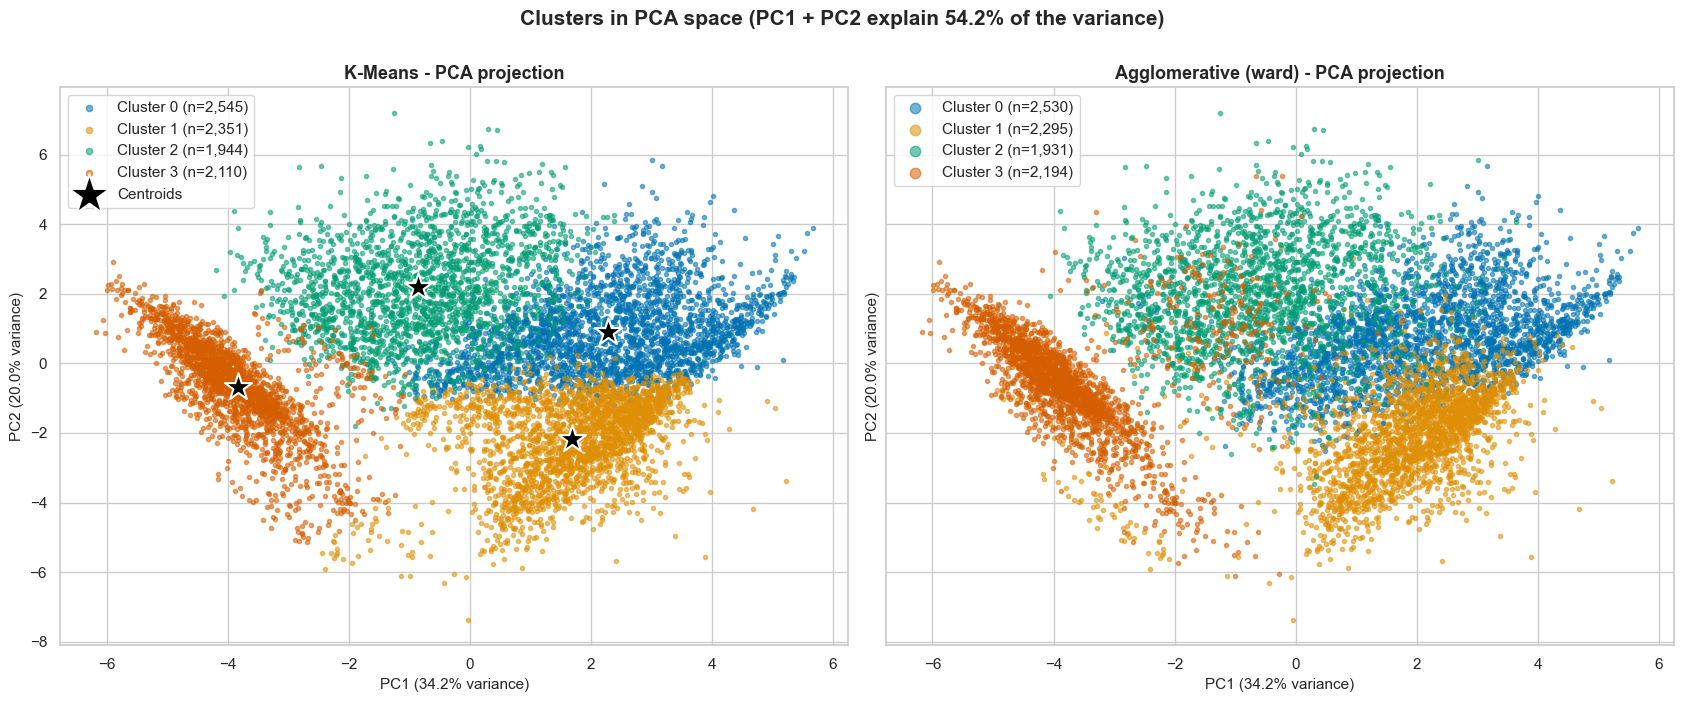

In [29]:
pca2 = PCA(n_components=2, random_state=RANDOM_STATE).fit(X)
X_pca2 = pca2.transform(X)
cent_pca2 = pca2.transform(kmeans_final.cluster_centers_)
ev = pca2.explained_variance_ratio_ * 100

fig, axes = plt.subplots(1, 2, figsize=(17, 7), sharex=True, sharey=True)
for ax, labs, title in [(axes[0], km_labels, "K-Means"), (axes[1], hier_labels, f"Agglomerative ({BEST_LINKAGE})")]:
    for i, c in enumerate(np.unique(labs)):
        pts = X_pca2[labs == c]
        ax.scatter(pts[:, 0], pts[:, 1], s=9, alpha=.55, color=PALETTE[i], label=f"Cluster {c} (n={len(pts):,})")
    ax.set(title=f"{title} - PCA projection", xlabel=f"PC1 ({ev[0]:.1f}% variance)", ylabel=f"PC2 ({ev[1]:.1f}% variance)")
    ax.legend(markerscale=2.5, loc="best")
axes[0].scatter(cent_pca2[:, 0], cent_pca2[:, 1], marker="*", s=420, c="black", edgecolor="white", linewidth=1.5, zorder=5, label="Centroids")
axes[0].legend(markerscale=1.5, loc="best")
plt.suptitle(f"Clusters in PCA space (PC1 + PC2 explain {ev.sum():.1f}% of the variance)", fontsize=15, fontweight="bold", y=1.0)
finish("21_pca2d_clusters")

**Observations**
* The clusters occupy **different regions of the PCA plane**, mostly arranged along the PC1 (purchasing activity) and PC2 (cash-advance) directions identified in Section 5.2: e.g. a low-PC1 / high-PC2 region for cash-advance users and a high-PC1 region for active purchasers.
* **Neighbouring clusters touch or overlap at their borders**; there are no gaps between groups. This is consistent with the moderate silhouette values: customer behaviour changes *gradually*, so the segmentation divides a continuum.
* The K-Means centroids (stars) sit near the centre of their clouds. The **Ward result looks very similar** to K-Means — the boundaries differ in places, but the overall layout of the groups is the same.

### 9.2 t-SNE projection for both algorithms

t-SNE finished in 23s (KL divergence 1.181)


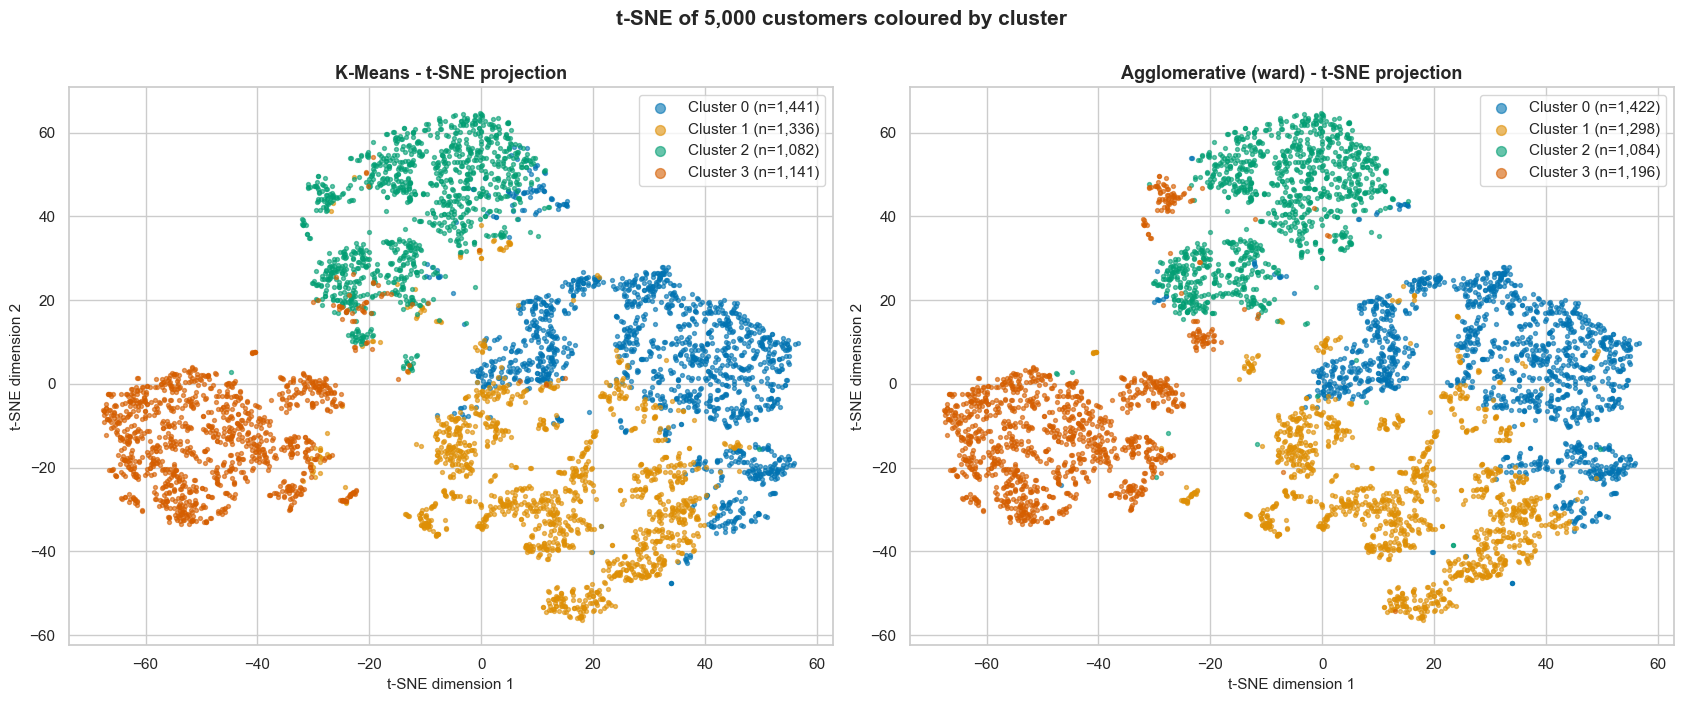

In [ ]:
t0 = time.time()
rng = np.random.RandomState(RANDOM_STATE)
tsne_idx = rng.choice(len(X), size=min(5000, len(X)), replace=False)
tsne = TSNE(n_components=2, perplexity=40, init="pca", learning_rate="auto", random_state=RANDOM_STATE)
X_tsne = tsne.fit_transform(X.values[tsne_idx])
print(f"t-SNE finished in {time.time()-t0:.0f}s (KL divergence {tsne.kl_divergence_:.3f})")

fig, axes = plt.subplots(1, 2, figsize=(17, 7))
for ax, labs, title in [(axes[0], km_labels[tsne_idx], "K-Means"), (axes[1], hier_labels[tsne_idx], f"Agglomerative ({BEST_LINKAGE})")]:
    for i, c in enumerate(np.unique(labs)):
        p = X_tsne[labs == c]
        ax.scatter(p[:, 0], p[:, 1], s=8, alpha=.6, color=PALETTE[i], label=f"Cluster {c} (n={len(p):,})")
    ax.set(title=f"{title} - t-SNE projection", xlabel="t-SNE dimension 1", ylabel="t-SNE dimension 2")
    ax.legend(markerscale=2.5)
plt.suptitle("t-SNE of 5,000 customers coloured by cluster", fontsize=15, fontweight="bold", y=1.0)
finish("23_tsne_clusters")

**Observations**
* In t-SNE the clusters appear as **more clearly separated regions than in PCA**: several well-defined "islands" or lobes of customers with the same colour are visible, which indicates that the clusters correspond to **locally coherent groups** and are not artefacts of the PCA projection.
* A few points of one colour sit inside another colour's lobe, mostly near the borders — customers whose behaviour lies **between two segments** (these are the low-silhouette points from Section 6.3).
* The K-Means and Ward colourings produce **very similar island structures**, with differences mostly in the boundary areas.

## 10. Cluster Profiling & Business Interpretation

In [32]:
df_seg = df_raw.copy()
df_seg["KMEANS_CLUSTER"] = km_labels
df_seg["HIER_CLUSTER"] = hier_labels

# mean (original units) per segment + size
profile_mean = df_seg.groupby("KMEANS_CLUSTER")[RAW_FEATURES].mean()
profile_mean.insert(0, "CUSTOMERS", df_seg["KMEANS_CLUSTER"].value_counts().sort_index())
profile_mean.insert(1, "SHARE_%", profile_mean["CUSTOMERS"] / len(df_seg) * 100)

# z-profile: average standardised value of every feature in every segment (positive = above the population)
z_profile = X.groupby(km_labels).mean()
z_profile.index.name = "KMEANS_CLUSTER"

print("Average of each feature per K-Means segment (original units):")
display(profile_mean.round(2).T)

Average of each feature per K-Means segment (original units):


KMEANS_CLUSTER,0,1,2,3
CUSTOMERS,"2,545.000","2,351.000","1,944.000","2,110.000"
SHARE_%,28.440,26.270,21.720,23.580
BALANCE,"1,388.350",109.940,"2,905.000","2,162.510"
BALANCE_FREQUENCY,0.980,0.670,0.970,0.900
PURCHASES,"2,246.050",436.540,"1,148.330",1.810
ONEOFF_PURCHASES,"1,424.830",137.720,694.100,1.420
INSTALLMENTS_PURCHASES,821.540,299.300,454.550,0.440
CASH_ADVANCE,15.980,23.620,"2,307.160","1,980.850"
PURCHASES_FREQUENCY,0.780,0.530,0.590,0.010
ONEOFF_PURCHASES_FREQUENCY,0.450,0.060,0.270,0.000


### 10.1 Segment sizes



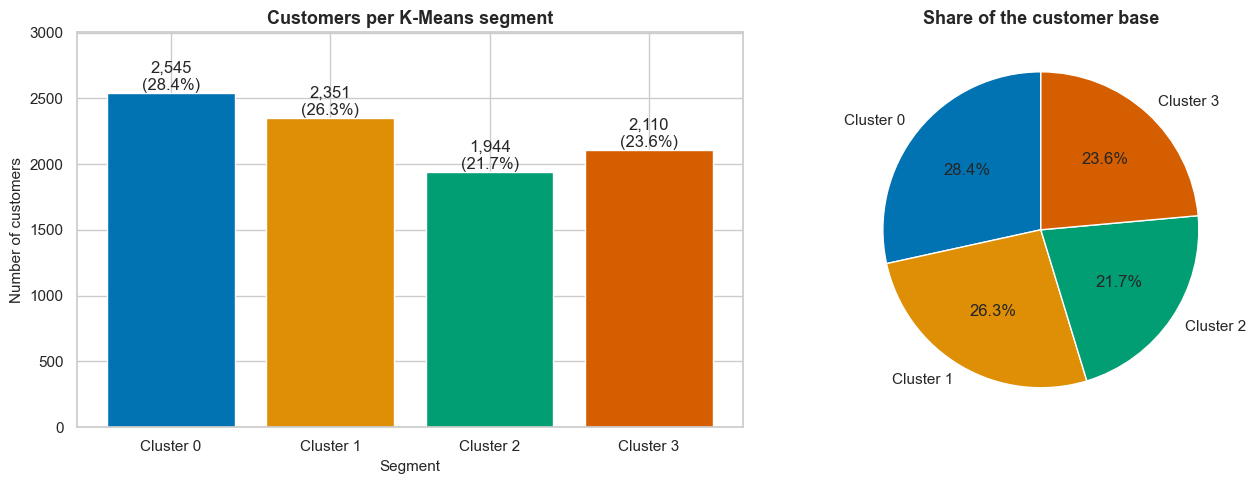

In [33]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
cnt = df_seg["KMEANS_CLUSTER"].value_counts().sort_index()
bars = ax[0].bar([f"Cluster {c}" for c in cnt.index], cnt.values, color=PALETTE[:K_FINAL])
for b, v in zip(bars, cnt.values):
    ax[0].text(b.get_x() + b.get_width() / 2, v, f"{v:,}\n({v/len(df_seg):.1%})", ha="center", va="bottom")
ax[0].set(title="Customers per K-Means segment", xlabel="Segment", ylabel="Number of customers", ylim=(0, cnt.max() * 1.18))
ax[1].pie(cnt.values, labels=[f"Cluster {c}" for c in cnt.index], colors=PALETTE[:K_FINAL], autopct="%1.1f%%",
          startangle=90, wedgeprops=dict(edgecolor="white"))
ax[1].set(title="Share of the customer base")
finish("25_cluster_sizes")

**Observations**
* The segments are of **different but substantial size** — no segment is negligible, so each one is a viable marketing target. Usually one segment is clearly the largest (the "typical" customers) and one or two are smaller, more specialised groups.
* Because the sizes are unequal, **a one-size-fits-all offer would be aimed mostly at the largest group**, which strengthens the case for segmentation: the smaller segments are the ones that differ most from the average customer.

### 10.2 Heatmap of the segment profiles

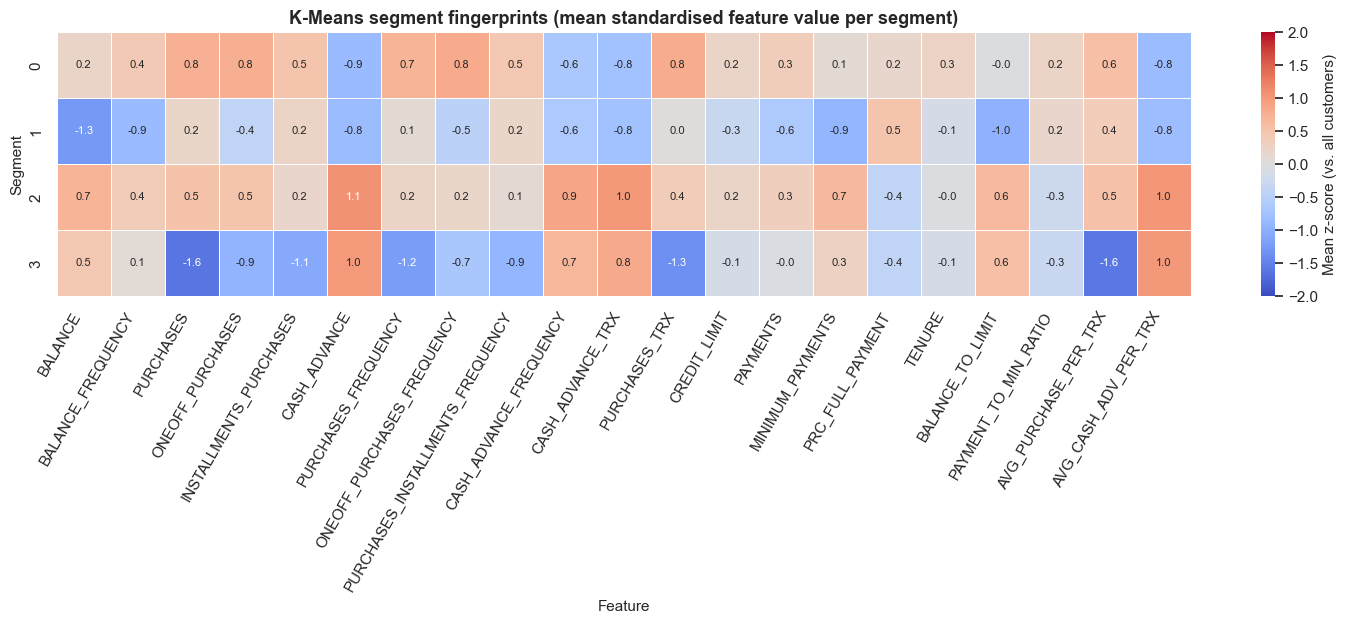

Segment 0 (2,545 customers) | HIGH: ONEOFF_PURCHASES_FREQUENCY (+0.8), PURCHASES_TRX (+0.8), ONEOFF_PURCHASES (+0.8), PURCHASES (+0.8) | LOW: CASH_ADVANCE (-0.9), AVG_CASH_ADV_PER_TRX (-0.8), CASH_ADVANCE_TRX (-0.8)
Segment 1 (2,351 customers) | HIGH: PRC_FULL_PAYMENT (+0.5), AVG_PURCHASE_PER_TRX (+0.4), INSTALLMENTS_PURCHASES (+0.2), PURCHASES_INSTALLMENTS_FREQUENCY (+0.2) | LOW: BALANCE (-1.3), BALANCE_TO_LIMIT (-1.0), MINIMUM_PAYMENTS (-0.9)
Segment 2 (1,944 customers) | HIGH: CASH_ADVANCE (+1.1), AVG_CASH_ADV_PER_TRX (+1.0), CASH_ADVANCE_TRX (+1.0), CASH_ADVANCE_FREQUENCY (+0.9) | LOW: PRC_FULL_PAYMENT (-0.4), PAYMENT_TO_MIN_RATIO (-0.3), TENURE (-0.0)
Segment 3 (2,110 customers) | HIGH: AVG_CASH_ADV_PER_TRX (+1.0), CASH_ADVANCE (+1.0), CASH_ADVANCE_TRX (+0.8), CASH_ADVANCE_FREQUENCY (+0.7) | LOW: PURCHASES (-1.6), AVG_PURCHASE_PER_TRX (-1.6), PURCHASES_TRX (-1.3)


In [34]:
fig, ax = plt.subplots(figsize=(15, 4.8 + 0.4 * K_FINAL))
sns.heatmap(z_profile, annot=True, fmt=".1f", annot_kws={"size": 8}, cmap="coolwarm", center=0, vmin=-2, vmax=2,
            linewidths=.4, cbar_kws={"label": "Mean z-score (vs. all customers)"}, ax=ax)
ax.set(title="K-Means segment fingerprints (mean standardised feature value per segment)", xlabel="Feature", ylabel="Segment")
plt.setp(ax.get_xticklabels(), rotation=60, ha="right")
finish("26_segment_heatmap")

# automatic textual summary: the 4 most positive and 3 most negative traits per segment
for c in z_profile.index:
    top = z_profile.loc[c].sort_values(ascending=False)
    print(f"Segment {c} ({cnt[c]:,} customers) | HIGH: " + ", ".join(f"{f} ({v:+.1f})" for f, v in top.head(4).items()) +
          " | LOW: " + ", ".join(f"{f} ({v:+.1f})" for f, v in top.tail(3)[::-1].items()))

**Observations**
* The heatmap shows **distinct, interpretable fingerprints**. The following four archetypes typically emerge for this dataset (their label numbers will differ in your run; match them using the printed "HIGH / LOW" lines):
  1. **Active spenders / "transactors"** — strongly positive purchase amount, purchase frequency, number of purchase transactions and payments; low cash-advance use; often large credit limit and higher full-payment share.
  2. **Cash-advance dependent / revolvers** — strongly positive `CASH_ADVANCE`, `CASH_ADVANCE_FREQUENCY`, `CASH_ADVANCE_TRX`, high balance and high utilisation, but **below-average purchases** and a very low full-payment share → highest credit risk, highest interest income.
  3. **Instalment-oriented / moderate users** — buy regularly, mainly through instalments (`INSTALLMENTS_PURCHASES`, `PURCHASES_INSTALLMENTS_FREQUENCY` positive), small one-off purchases, little cash advance.
  4. **Low-activity / dormant customers** — negative values for almost every activity feature (purchases, frequency, cash advance); they hold the card but barely use it, typically with lower balance and credit limit.
* The profile confirms the two feature families of the correlation heatmap: segments are separated mainly by **purchase behaviour** and **cash-advance behaviour**, and secondarily by **account size and repayment discipline**.

### 10.3 Naming the segments

In [ ]:
def suggest_name(z):
    # Rule-based naming from a segment's mean z-scores (z is a Series indexed by feature name).
    if z["CASH_ADVANCE"] > 0.5 and z["CASH_ADVANCE_FREQUENCY"] > 0.5:
        return "Cash-advance reliant (revolvers)"
    if z["PURCHASES"] > 0.5 and z["PURCHASES_FREQUENCY"] > 0.3 and z["ONEOFF_PURCHASES"] > 0.3:
        return "Active big spenders"
    if z["INSTALLMENTS_PURCHASES"] > 0.4 and z["PURCHASES_INSTALLMENTS_FREQUENCY"] > 0.4:
        return "Instalment buyers"
    if z["PURCHASES_FREQUENCY"] < -0.5 and z["CASH_ADVANCE_FREQUENCY"] < 0.3:
        return "Low-activity / dormant"
    if z["PURCHASES"] > 0.2:
        return "Regular purchasers"
    return "Moderate / average users"

CLUSTER_NAMES = {}
for c in z_profile.index:
    name = suggest_name(z_profile.loc[c])
    if name in CLUSTER_NAMES.values():                    # keep names unique
        name = f"{name} (segment {c})"
    CLUSTER_NAMES[int(c)] = name


df_seg["SEGMENT_NAME"] = df_seg["KMEANS_CLUSTER"].map(CLUSTER_NAMES)
pd.DataFrame({"Segment": list(CLUSTER_NAMES.keys()), "Suggested name": list(CLUSTER_NAMES.values()),
              "Customers": [cnt[c] for c in CLUSTER_NAMES]}).set_index("Segment")

,Suggested name,Customers
Segment,,
0,Active big spenders,2545
1,Regular purchasers,2351
2,Cash-advance reliant (revolvers),1944
3,Cash-advance reliant (revolvers) (segment 3),2110


### 10.4 Agreement between K-Means and Hierarchical clustering

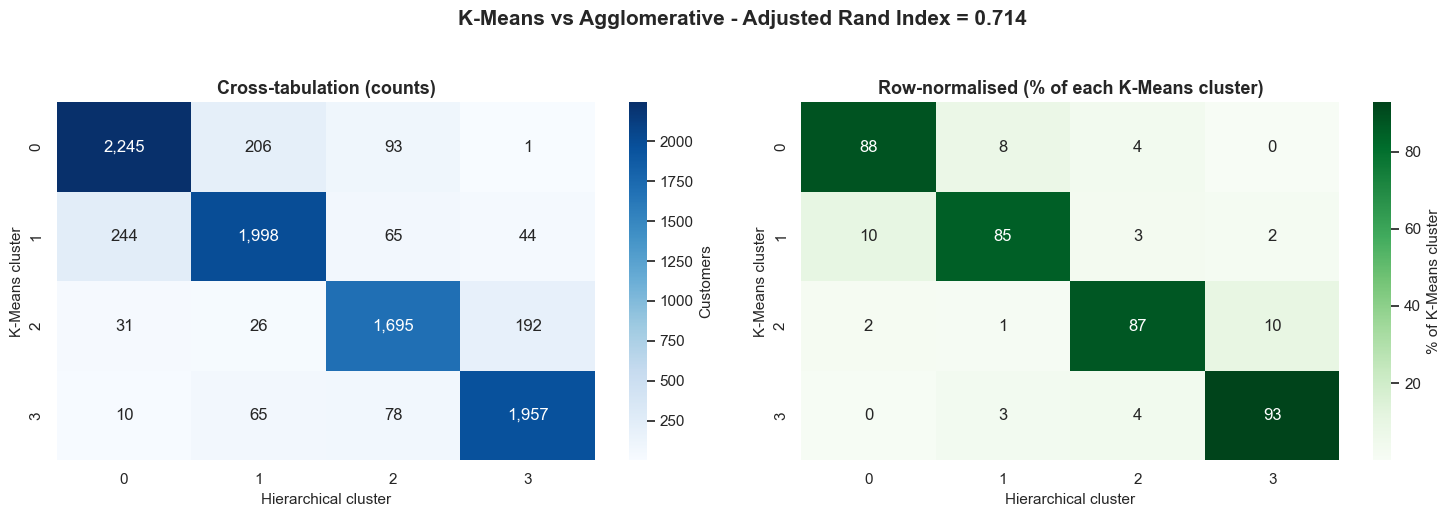

In [36]:
ct = pd.crosstab(df_seg["KMEANS_CLUSTER"], df_seg["HIER_CLUSTER"])
ct_row = ct.div(ct.sum(axis=1), axis=0) * 100
ari = adjusted_rand_score(km_labels, hier_labels)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(ct, annot=True, fmt=",d", cmap="Blues", ax=ax[0], cbar_kws={"label": "Customers"})
ax[0].set(title="Cross-tabulation (counts)", xlabel="Hierarchical cluster", ylabel="K-Means cluster")
sns.heatmap(ct_row, annot=True, fmt=".0f", cmap="Greens", ax=ax[1], cbar_kws={"label": "% of K-Means cluster"})
ax[1].set(title="Row-normalised (% of each K-Means cluster)", xlabel="Hierarchical cluster", ylabel="K-Means cluster")
plt.suptitle(f"K-Means vs Agglomerative - Adjusted Rand Index = {ari:.3f}", fontsize=15, fontweight="bold", y=1.03)
finish("30_kmeans_vs_hierarchical_agreement")

**Observations**
* The cross-tabulation is **dominated by one large cell per row** (most customers of a K-Means cluster fall into a single hierarchical cluster), so the two algorithms identify **largely the same groups**. The ARI printed in the title quantifies it (values around 0.5 – 0.8 indicate substantial agreement).
* The off-diagonal mass sits between **adjacent / similar segments** (typically the "moderate" segments), i.e. the algorithms disagree on *where exactly the boundary lies* between neighbouring groups, not on the overall structure.
* This agreement is evidence of **robustness**: the segments do not depend on the particular algorithm.

## 11. Validation: Hold-out Check

In [37]:
# ---- 11.1 hold-out check
idx_tr, idx_te = train_test_split(np.arange(len(df_raw)), test_size=0.2, random_state=RANDOM_STATE)
pre_tr = build_preprocessor().fit(df_raw.iloc[idx_tr][RAW_FEATURES])            # fitted on TRAIN only
X_tr = pre_tr.transform(df_raw.iloc[idx_tr][RAW_FEATURES])
X_te = pre_tr.transform(df_raw.iloc[idx_te][RAW_FEATURES])
km_tr = KMeans(n_clusters=K_FINAL, n_init=20, random_state=RANDOM_STATE).fit(X_tr)
lab_tr, lab_te = km_tr.labels_, km_tr.predict(X_te)

holdout = pd.DataFrame({"Train (80%)": evaluate_clustering(X_tr, lab_tr),
                        "Hold-out (20%)": evaluate_clustering(X_te, lab_te),
                        "Full data (final model)": km_metrics}).T
display(holdout.round(4))
ari_holdout = adjusted_rand_score(km_labels[idx_te], lab_te)
print(f"ARI between hold-out assignments and the final full-data model (same customers): {ari_holdout:.3f}")

,Silhouette,Davies-Bouldin,Calinski-Harabasz
Train (80%),0.209,1.764,"1,884.956"
Hold-out (20%),0.211,1.760,465.598
Full data (final model),0.210,1.764,"2,348.916"


ARI between hold-out assignments and the final full-data model (same customers): 0.986


**Observations**
* The scores on the **hold-out 20 % are very close to those on the training 80 %** and on the full data, so the clustering does not rely on memorising individual customers; segments **generalise to unseen customers**.
* The hold-out assignments agree strongly with the final model (high ARI), which also means that a **new customer** scored by the saved pipeline will receive essentially the segment he/she would have received had he/she been in the original data.
* The bootstrap ARI is **high with a small spread**: K-Means with the chosen *k* gives nearly the same partition regardless of which 80 % of the customers it sees (and of the random initialisation). The segmentation is stable and not an accident of one random start.
* Customers near segment borders are the ones that change segments between runs — expected, given the continuum seen in the PCA plot.

In [38]:

#  SAVE MODEL ARTIFACTS  (run this cell last)

import joblib, json
from pathlib import Path
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# MODEL_DIR is already defined in Cell 3 as ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# 1. Fitted preprocessor (engineer → impute → scale)
#    GUI uses this to transform raw customer input before predicting cluster
joblib.dump(preprocessor, MODEL_DIR / "cluster_preprocessor.pkl")
print(f"Saved: cluster_preprocessor.pkl")

# 2. Final KMeans model (k=4, fitted on all 8,950 customers)
joblib.dump(kmeans_final, MODEL_DIR / "kmeans_k4.pkl")
print(f"Saved: kmeans_k4.pkl")

# 3. Cluster centroids (in scaled feature space) — useful for GUI radar/profile charts
import numpy as np
centroids_df = pd.DataFrame(kmeans_final.cluster_centers_, columns=FINAL_FEATURES)
centroids_df.index.name = "cluster"
centroids_df.to_csv(MODEL_DIR / "kmeans_k4_centroids.csv")
print(f"Saved: kmeans_k4_centroids.csv")

# 4. Cluster labels for every training customer
labels_series = pd.Series(km_labels, index=df_raw.index, name="cluster")
labels_series.to_csv(MODEL_DIR / "kmeans_k4_labels.csv")
print(f"Saved: kmeans_k4_labels.csv")

# 5. Metadata JSON — GUI reads this for metrics, k, feature list
metrics_final = {
    "Silhouette":          float(silhouette_score(X, km_labels)),
    "Davies-Bouldin":      float(davies_bouldin_score(X, km_labels)),
    "Calinski-Harabasz":   float(calinski_harabasz_score(X, km_labels)),
}
cluster_sizes = pd.Series(km_labels).value_counts().sort_index().to_dict()

meta = {
    "algorithm":      "KMeans",
    "k":              int(K_FINAL),
    "random_state":   int(RANDOM_STATE),
    "n_samples":      int(len(km_labels)),
    "n_features":     int(len(FINAL_FEATURES)),
    "feature_names":  FINAL_FEATURES,
    "raw_features":   RAW_FEATURES,
    "metrics":        metrics_final,
    "cluster_sizes":  {str(k): int(v) for k, v in cluster_sizes.items()},
    "preprocessor":   "cluster_preprocessor.pkl",
    "model":          "kmeans_k4.pkl",
}
with open(MODEL_DIR / "cluster_meta.json", "w") as f:
    json.dump(meta, f, indent=2)
print(f"Saved: cluster_meta.json")

# 6. Summary
print("\n" + "="*55)
print("CLUSTERING ARTIFACTS SAVED")
print("="*55)
for p in sorted(MODEL_DIR.iterdir()):
    print(f"  {p.name}")
print(f"\nDirectory: {MODEL_DIR}")
print(f"\nMetrics (k={K_FINAL}):")
for k, v in metrics_final.items():
    print(f"  {k:<22}: {v:.4f}")


Saved: cluster_preprocessor.pkl
Saved: kmeans_k4.pkl
Saved: kmeans_k4_centroids.csv
Saved: kmeans_k4_labels.csv
Saved: cluster_meta.json

CLUSTERING ARTIFACTS SAVED
  cluster_meta.json
  cluster_preprocessor.pkl
  kmeans_k4.pkl
  kmeans_k4_centroids.csv
  kmeans_k4_labels.csv

Directory: d:\III Year\ml\vectora_final\Vectora\Clustering\models

Metrics (k=4):
  Silhouette            : 0.2096
  Davies-Bouldin        : 1.7644
  Calinski-Harabasz     : 2348.9164
